# Traffic Sign Recognition for Autonomous Vehicles Using Deep Learning
### A Comparative Study of CNN and YOLO-Based Approaches

## Part 1 : Dataset & Preprocessing

### 1.1 Import Required Libraries

In [ ]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.21.0


### 1.2 Dataset Loading and Directory Setup

In [ ]:
!wget -q --show-progress "https://www.kaggle.com/api/v1/datasets/download/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign" -O /content/gtsrb.zip

!unzip -q /content/gtsrb.zip -d /content/gtsrb

!ls /content/gtsrb

/content/gtsrb.zip  100%[===================>] 611.85M  44.4MB/s    in 7.2s    
meta  Meta  Meta.csv  test  Test  Test.csv  train  Train  Train.csv


In [ ]:
DATASET_PATH = "/content/gtsrb"

DATASET_ROOT = Path(DATASET_PATH)
TRAIN_DIR = DATASET_ROOT / "Train"
TEST_CSV  = DATASET_ROOT / "Test.csv"

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

if not TRAIN_DIR.exists() or not TEST_CSV.exists():
    raise FileNotFoundError(
        f"Could not find 'Train' and 'Test.csv' inside: {DATASET_ROOT}\n"
        "Set DATASET_PATH to the folder that contains Train/, Test/, Meta/ and Test.csv."
    )

print("Dataset structure:")
for name in ["Train", "Test", "Meta", "Test.csv"]:
    print(f"  {name:9s} exists: {(DATASET_ROOT / name).exists()}")

Dataset structure:
  Train     exists: True
  Test      exists: True
  Meta      exists: True
  Test.csv  exists: True


### 1.3 Dataset Structure and Class Inspection

In [ ]:
CLASS_NAMES = {
    0: "Speed limit (20km/h)", 1: "Speed limit (30km/h)", 2: "Speed limit (50km/h)",
    3: "Speed limit (60km/h)", 4: "Speed limit (70km/h)", 5: "Speed limit (80km/h)",
    6: "End of speed limit (80km/h)", 7: "Speed limit (100km/h)", 8: "Speed limit (120km/h)",
    9: "No passing", 10: "No passing for vehicles over 3.5t",
    11: "Right-of-way at next intersection", 12: "Priority road", 13: "Yield", 14: "Stop",
    15: "No vehicles", 16: "Vehicles over 3.5t prohibited", 17: "No entry",
    18: "General caution", 19: "Dangerous curve to the left", 20: "Dangerous curve to the right",
    21: "Double curve", 22: "Bumpy road", 23: "Slippery road", 24: "Road narrows on the right",
    25: "Road work", 26: "Traffic signals", 27: "Pedestrians", 28: "Children crossing",
    29: "Bicycles crossing", 30: "Beware of ice/snow", 31: "Wild animals crossing",
    32: "End of all speed and passing limits", 33: "Turn right ahead", 34: "Turn left ahead",
    35: "Ahead only", 36: "Go straight or right", 37: "Go straight or left", 38: "Keep right",
    39: "Keep left", 40: "Roundabout mandatory", 41: "End of no passing",
    42: "End of no passing by vehicles over 3.5t",
}

class_folders = sorted(
    [folder for folder in TRAIN_DIR.iterdir() if folder.is_dir() and folder.name.isdigit()],
    key=lambda folder: int(folder.name),
)
train_df = pd.DataFrame(
    [{"path": image_path, "class_id": int(folder.name), "source": "train"}
     for folder in class_folders
     for image_path in sorted(folder.glob("*.png"))]
)

test_csv = pd.read_csv(TEST_CSV)
test_df = pd.DataFrame({
    "path": [DATASET_ROOT / p for p in test_csv["Path"]],
    "class_id": test_csv["ClassId"].astype(int),
    "source": "test",
})

all_df = pd.concat([train_df, test_df], ignore_index=True)

print(f"Number of classes        : {len(class_folders)}")
print(f"Number of training images: {len(train_df):,}")
print(f"Number of test images    : {len(test_df):,}")
print(f"Total images             : {len(all_df):,}")

Number of classes        : 43
Number of training images: 39,209
Number of test images    : 12,630
Total images             : 51,839


In [ ]:
class_counts = train_df["class_id"].value_counts().sort_index()

class_counts_df = pd.DataFrame({
    "Class Name": class_counts.index.map(CLASS_NAMES),
    "Number of Images": class_counts.values,
}, index=class_counts.index.rename("Class ID"))
class_counts_df

,Class Name,Number of Images
Class ID,,
0,Speed limit (20km/h),210
1,Speed limit (30km/h),2220
2,Speed limit (50km/h),2250
3,Speed limit (60km/h),1410
4,Speed limit (70km/h),1980
5,Speed limit (80km/h),1860
6,End of speed limit (80km/h),420
7,Speed limit (100km/h),1440
8,Speed limit (120km/h),1410


### 1.4 Visualize Sample Traffic Sign Images

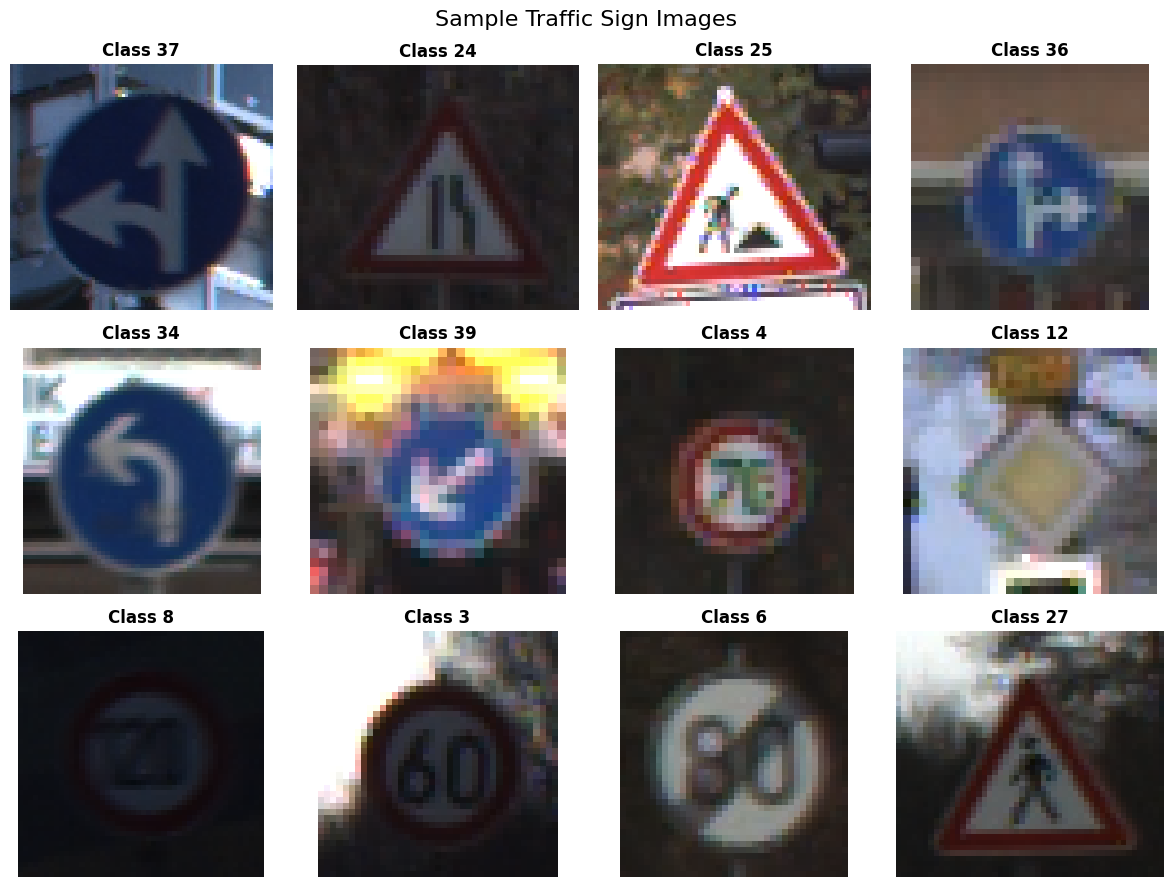

In [ ]:
samples = train_df.groupby("class_id").sample(1, random_state=SEED).sample(12, random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (_, row) in zip(axes.ravel(), samples.iterrows()):
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.set_title(f"Class {row['class_id']}")
    ax.axis("off")
plt.suptitle("Sample Traffic Sign Images", fontsize=16)
plt.tight_layout()
plt.show()

Variation within a single class:

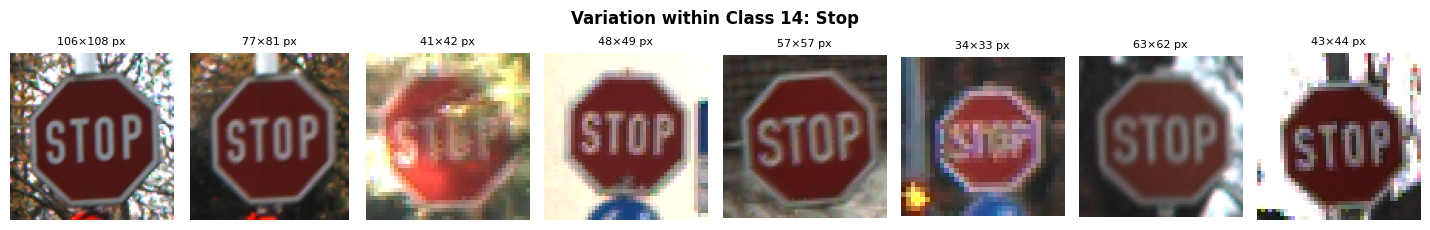

In [ ]:
CLASS_TO_INSPECT = 14
N_EXAMPLES = 8

class_images = train_df[train_df["class_id"] == CLASS_TO_INSPECT]
examples = class_images.sample(min(N_EXAMPLES, len(class_images)), random_state=SEED)

fig, axes = plt.subplots(1, len(examples), figsize=(len(examples) * 1.8, 2.3))
for ax, image_path in zip(np.atleast_1d(axes), examples["path"]):
    img = Image.open(image_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{img.width}×{img.height} px", fontsize=8, fontweight="normal")
    ax.axis("off")
fig.suptitle(f"Variation within Class {CLASS_TO_INSPECT}: {CLASS_NAMES[CLASS_TO_INSPECT]}",
             fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

### 1.5 Analyze Class Distribution

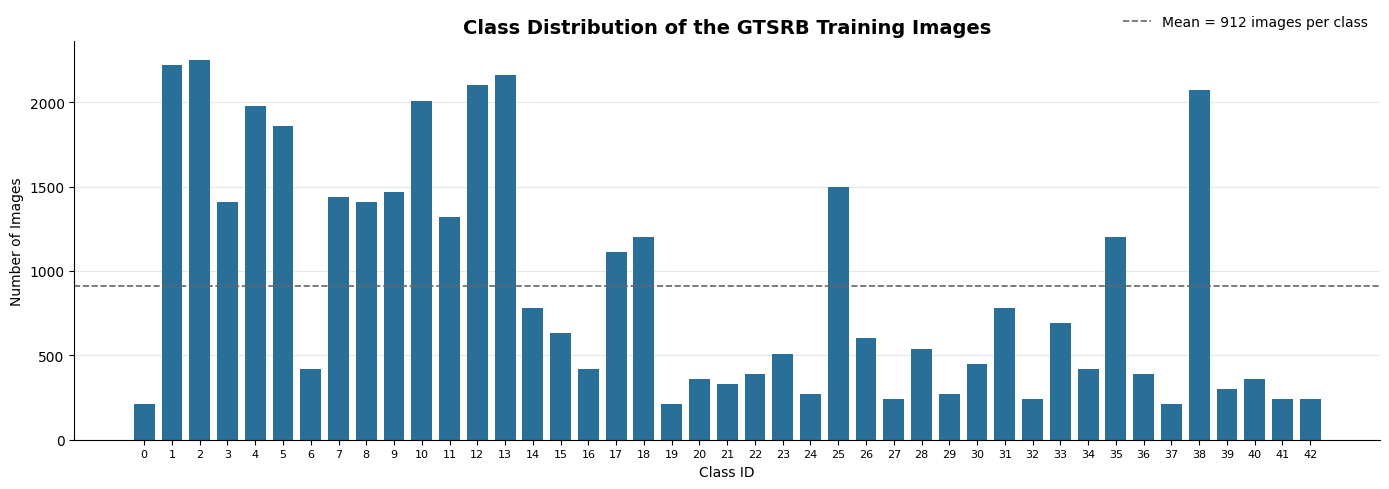

Most frequent class : 2 (Speed limit (50km/h)) with 2,250 images
Least frequent class: 0 (Speed limit (20km/h)) with 210 images
Imbalance ratio (max / min): 10.7


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(class_counts.index, class_counts.values, color="#2a6f97", width=0.75)
ax.axhline(class_counts.mean(), color="#666666", linestyle="--", linewidth=1.2,
           label=f"Mean = {class_counts.mean():.0f} images per class")
ax.set_title("Class Distribution of the GTSRB Training Images", fontsize=14)
ax.set_xlabel("Class ID")
ax.set_ylabel("Number of Images")
ax.set_xticks(class_counts.index)
ax.tick_params(axis="x", labelsize=8)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

most, least = class_counts.idxmax(), class_counts.idxmin()
print(f"Most frequent class : {most} ({CLASS_NAMES[most]}) with {class_counts.max():,} images")
print(f"Least frequent class: {least} ({CLASS_NAMES[least]}) with {class_counts.min():,} images")
print(f"Imbalance ratio (max / min): {class_counts.max() / class_counts.min():.1f}")

### 1.6 Image Size and Data Quality Inspection

In [ ]:
widths, heights, readable = [], [], []

for image_path in all_df["path"]:
    try:
        with Image.open(image_path) as img:
            img.load()
            widths.append(img.width)
            heights.append(img.height)
            readable.append(True)
    except Exception:
        widths.append(np.nan)
        heights.append(np.nan)
        readable.append(False)

all_df["width"] = widths
all_df["height"] = heights
all_df["readable"] = readable

corrupted = all_df[~all_df["readable"]]
print(f"Images checked        : {len(all_df):,}")
print(f"Successfully opened   : {all_df['readable'].sum():,}")
print(f"Corrupted / unreadable: {len(corrupted):,}")
if len(corrupted) > 0:
    display(corrupted[["path", "class_id", "source"]])

n_sizes = all_df.groupby(["width", "height"]).ngroups
print(f"\nNumber of different image sizes: {n_sizes:,} (all the same size: {n_sizes == 1})")
display(all_df[["width", "height"]].describe().round(1))

Images checked        : 51,839
Successfully opened   : 51,839
Corrupted / unreadable: 0

Number of different image sizes: 3,338 (all the same size: False)


,width,height
count,51839.0,51839.0
mean,50.8,50.3
std,24.5,23.3
min,25.0,25.0
25%,34.0,35.0
50%,43.0,43.0
75%,58.0,58.0
max,266.0,232.0


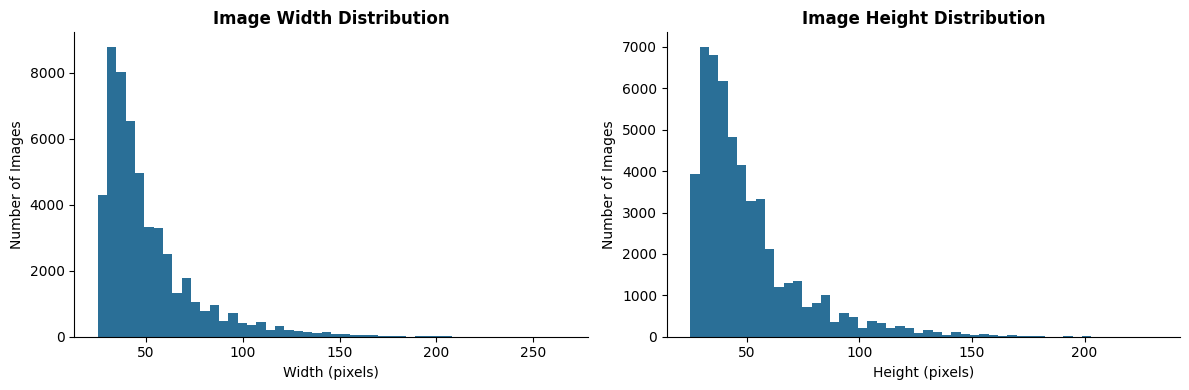

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, ["width", "height"]):
    ax.hist(all_df[column].dropna(), bins=50, color="#2a6f97")
    ax.set_title(f"Image {column.capitalize()} Distribution")
    ax.set_xlabel(f"{column.capitalize()} (pixels)")
    ax.set_ylabel("Number of Images")
plt.tight_layout()
plt.show()

### 1.7 Image Resizing

In [ ]:
IMG_SIZE = (64, 64)

def load_and_resize(path):
    """Open an image, convert it to RGB and resize it to IMG_SIZE."""
    with Image.open(path) as img:
        return np.array(img.convert("RGB").resize(IMG_SIZE), dtype=np.uint8)

data_df = all_df[all_df["readable"]].reset_index(drop=True)
n_excluded = len(all_df) - len(data_df)

X_all = np.array([load_and_resize(path) for path in data_df["path"]])

print(f"Corrupted images excluded: {n_excluded}")
print(f"Resized images           : {X_all.shape}  ({X_all.dtype})")

Corrupted images excluded: 0
Resized images           : (51839, 64, 64, 3)  (uint8)


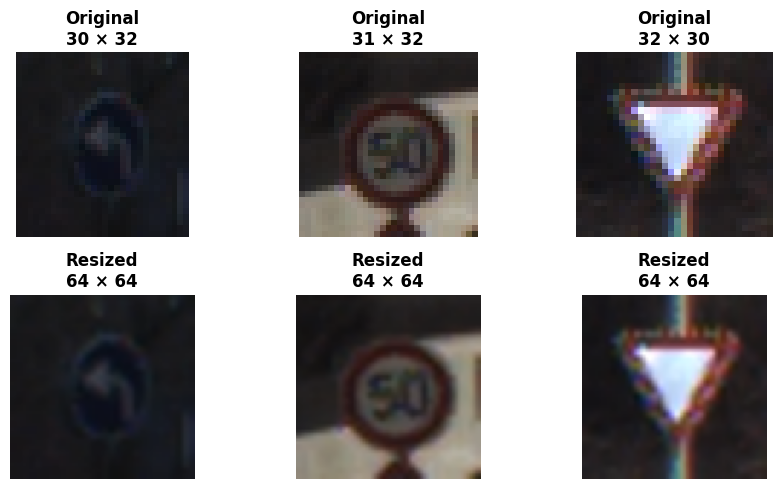

In [ ]:
# Before vs. after resizing
rng = np.random.default_rng(SEED)
demo_idx = rng.choice(len(data_df), size=3, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(9, 5))
for col, idx in enumerate(demo_idx):
    original = Image.open(data_df.loc[idx, "path"]).convert("RGB")
    axes[0, col].imshow(original)
    axes[0, col].set_title(f"Original\n{original.width} × {original.height}")
    axes[1, col].imshow(X_all[idx])
    axes[1, col].set_title(f"Resized\n{IMG_SIZE[0]} × {IMG_SIZE[1]}")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

### 1.8 Label Preparation

In [ ]:
y_all = data_df["class_id"].to_numpy(dtype=np.int32)

NUM_CLASSES = len(CLASS_NAMES)
LABEL_NAMES = [CLASS_NAMES[i] for i in range(NUM_CLASSES)]

print("Label array shape:", y_all.shape)
print("Number of classes:", NUM_CLASSES)
print("Label range      :", y_all.min(), "to", y_all.max())

Label array shape: (51839,)
Number of classes: 43
Label range      : 0 to 42


### 1.9 Train, Validation, and Test Split

In [ ]:
VALIDATION_SPLIT = 0.15

track_ids = data_df["path"].apply(lambda p: Path(p).stem.rsplit("_", 1)[0]).to_numpy()

is_train = (data_df["source"] == "train").to_numpy()
train_pool_idx = np.where(is_train)[0]
test_idx = np.where(~is_train)[0]

splitter = StratifiedGroupKFold(n_splits=round(1 / VALIDATION_SPLIT), shuffle=True, random_state=SEED)
train_pos, val_pos = next(splitter.split(train_pool_idx, y_all[train_pool_idx], track_ids[train_pool_idx]))
train_idx, val_idx = train_pool_idx[train_pos], train_pool_idx[val_pos]

SPLIT_STRATEGY = ("Official Test set as test; official Train split into train/validation "
                  "(stratified by class, grouped by track)")
print(f"Train images     : {len(train_idx):,}")
print(f"Validation images: {len(val_idx):,}  ({len(val_idx) / len(train_pool_idx):.1%} of the official Train set)")
print(f"Test images      : {len(test_idx):,}")

Train images     : 33,599
Validation images: 5,610  (14.3% of the official Train set)
Test images      : 12,630


### Verifying the split (no leakage, stratification)

No image or track appears in more than one subset.
Classes present in each subset: {'Train': 43, 'Validation': 41, 'Test': 43}


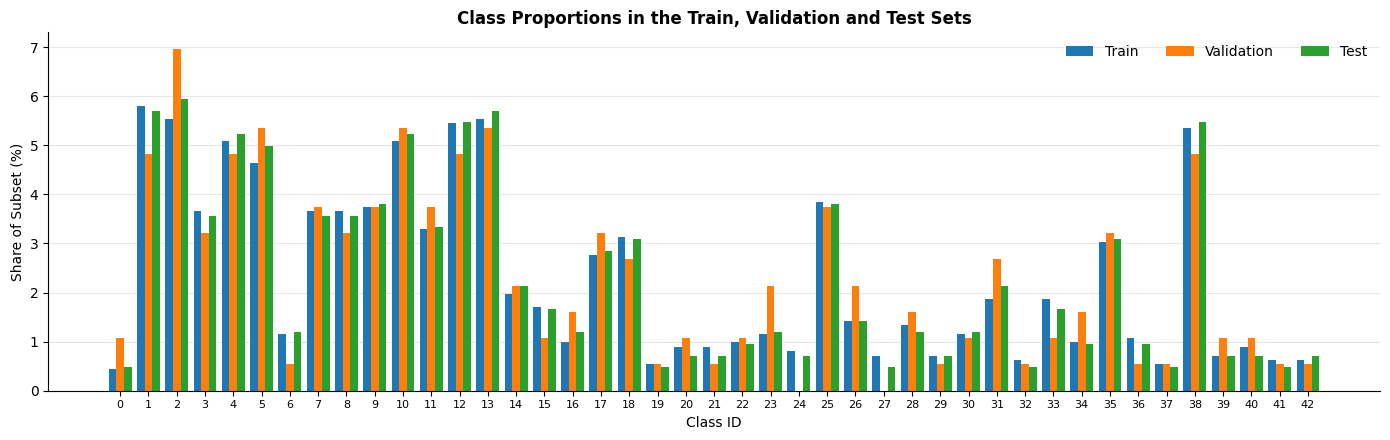

In [ ]:
assert not set(train_idx) & set(val_idx), "Overlap between train and validation!"
assert not set(train_idx) & set(test_idx), "Overlap between train and test!"
assert not set(val_idx) & set(test_idx), "Overlap between validation and test!"
assert not set(track_ids[train_idx]) & set(track_ids[val_idx]), "A track is in both train and validation!"
print("No image or track appears in more than one subset.")

subsets = {"Train": train_idx, "Validation": val_idx, "Test": test_idx}
proportions = pd.DataFrame({
    name: pd.Series(y_all[idx]).value_counts(normalize=True).reindex(range(NUM_CLASSES), fill_value=0)
    for name, idx in subsets.items()
})
print("Classes present in each subset:", {name: len(np.unique(y_all[idx])) for name, idx in subsets.items()})

fig, ax = plt.subplots(figsize=(14, 4.5))
width = 0.27
for k, name in enumerate(proportions.columns):
    ax.bar(proportions.index + (k - 1) * width, proportions[name] * 100, width=width, label=name)
ax.set_title("Class Proportions in the Train, Validation and Test Sets")
ax.set_xlabel("Class ID")
ax.set_ylabel("Share of Subset (%)")
ax.set_xticks(proportions.index)
ax.tick_params(axis="x", labelsize=8)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
plt.show()

### 1.10 Pixel Normalization

In [ ]:
X_train = X_all[train_idx].astype(np.float32) / 255.0
X_val   = X_all[val_idx].astype(np.float32) / 255.0
X_test  = X_all[test_idx].astype(np.float32) / 255.0

y_train = y_all[train_idx]
y_val   = y_all[val_idx]
y_test  = y_all[test_idx]

del X_all

for name, X in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    print(f"{name:8s}: shape={X.shape}, dtype={X.dtype}, min={X.min():.1f}, max={X.max():.1f}")

X_train : shape=(33599, 64, 64, 3), dtype=float32, min=0.0, max=1.0
X_val   : shape=(5610, 64, 64, 3), dtype=float32, min=0.0, max=1.0
X_test  : shape=(12630, 64, 64, 3), dtype=float32, min=0.0, max=1.0


### 1.11 Data Augmentation

In [ ]:
data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(factor=10 / 360, fill_mode="nearest", seed=SEED),
        layers.RandomZoom(height_factor=0.10, fill_mode="nearest", seed=SEED),
        layers.RandomTranslation(height_factor=0.10, width_factor=0.10,
                                 fill_mode="nearest", seed=SEED),
        layers.RandomBrightness(factor=0.20, value_range=(0.0, 1.0), seed=SEED),
    ],
    name="data_augmentation",
)

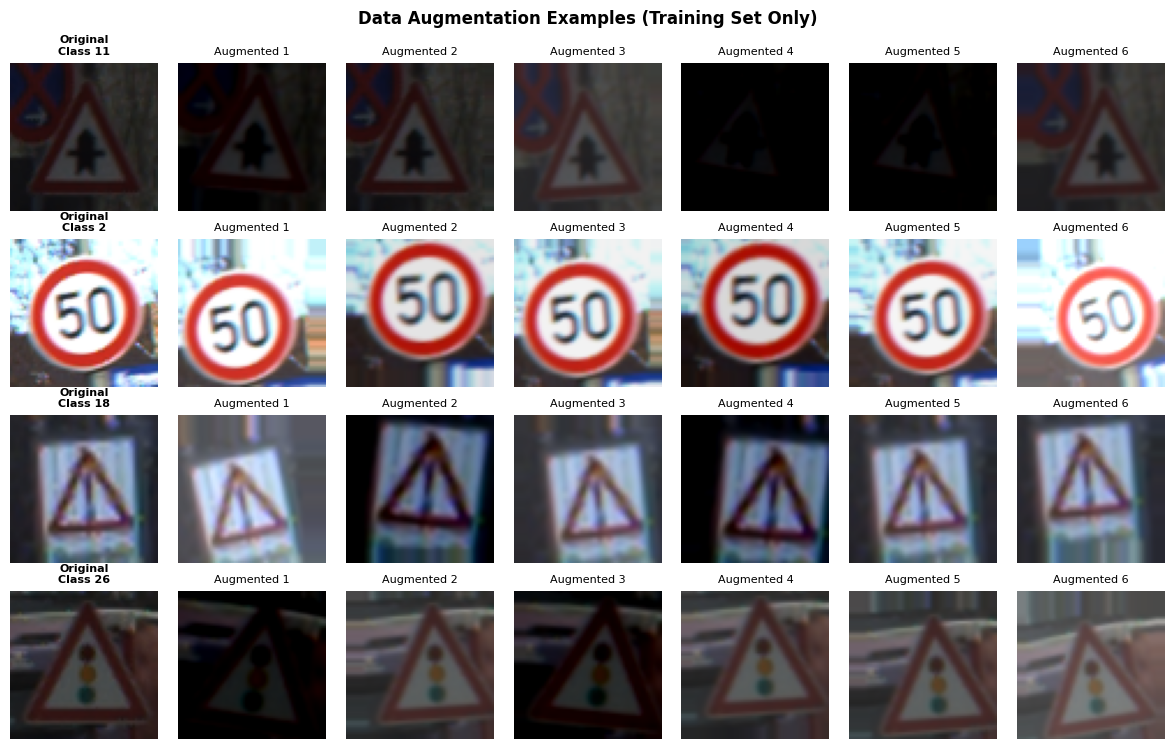

In [ ]:
N_IMAGES, N_AUGMENTED = 4, 6
rng = np.random.default_rng(SEED)
chosen = rng.choice(len(X_train), size=N_IMAGES, replace=False)

fig, axes = plt.subplots(N_IMAGES, N_AUGMENTED + 1, figsize=((N_AUGMENTED + 1) * 1.7, N_IMAGES * 1.9))
for row, idx in enumerate(chosen):
    image = X_train[idx]
    batch = np.repeat(image[None, ...], N_AUGMENTED, axis=0)
    augmented = data_augmentation(batch, training=True).numpy()

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original\nClass {y_train[idx]}", fontsize=8)
    for col in range(N_AUGMENTED):
        axes[row, col + 1].imshow(np.clip(augmented[col], 0, 1))
        axes[row, col + 1].set_title(f"Augmented {col + 1}", fontsize=8, fontweight="normal")

for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Data Augmentation Examples (Training Set Only)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "augmentation_examples.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.12 Final Dataset Preparation

In [ ]:
BATCH_SIZE = 64
SHUFFLE_BUFFER = 2048
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(X, y, training=False):
    """Batched tf.data pipeline. Shuffling and augmentation ONLY when training=True."""
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(SHUFFLE_BUFFER, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(lambda images, labels: (data_augmentation(images, training=True), labels),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

order = np.random.default_rng(SEED).permutation(len(X_train))
X_train, y_train = X_train[order], y_train[order]

train_ds = make_dataset(X_train, y_train, training=True)
val_ds   = make_dataset(X_val, y_val)
test_ds  = make_dataset(X_test, y_test)

INPUT_SHAPE = X_train.shape[1:]

for name, ds in [("train_ds", train_ds), ("val_ds", val_ds), ("test_ds", test_ds)]:
    images, labels = next(iter(ds))
    print(f"{name:8s} batch: images {tuple(images.shape)}, labels {tuple(labels.shape)}, "
          f"pixel range [{float(tf.reduce_min(images)):.2f}, {float(tf.reduce_max(images)):.2f}]")

train_ds batch: images (64, 64, 64, 3), labels (64,), pixel range [0.00, 1.00]
val_ds   batch: images (64, 64, 64, 3), labels (64,), pixel range [0.00, 1.00]
test_ds  batch: images (64, 64, 64, 3), labels (64,), pixel range [0.00, 1.00]


### Preprocessing Summary

In [ ]:
summary = pd.DataFrame(
    [
        ("Dataset", "GTSRB — German Traffic Sign Recognition Benchmark"),
        ("Split strategy", SPLIT_STRATEGY),
        ("Number of training images", f"{len(X_train):,}"),
        ("Number of validation images", f"{len(X_val):,}"),
        ("Number of testing images", f"{len(X_test):,}"),
        ("Corrupted images excluded", f"{n_excluded:,}"),
        ("Input shape (H, W, C)", str(INPUT_SHAPE)),
        ("Number of classes", str(NUM_CLASSES)),
        ("Pixel values", f"float32 in [{X_train.min():.1f}, {X_train.max():.1f}]"),
        ("Label format", "Integer class IDs 0-42 (int32) — use sparse_categorical_crossentropy"),
        ("Data augmentation", "Training set only, inside train_ds (rotation, zoom, translation, brightness)"),
        ("Augmentation on validation/test", "No"),
        ("Batch size", str(BATCH_SIZE)),
        ("Random seed", str(SEED)),
    ],
    columns=["Item", "Value"],
).set_index("Item")

summary

,Value
Item,
Dataset,GTSRB — German Traffic Sign Recognition Benchmark
Split strategy,Official Test set as test; official Train spli...
Number of training images,"33,599"
Number of validation images,"5,610"
Number of testing images,"12,630"
Corrupted images excluded,0
"Input shape (H, W, C)","(64, 64, 3)"
Number of classes,43
Pixel values,"float32 in [0.0, 1.0]"


## Part 2 : CNN DEVELOPMENT

### 2.1 Baseline CNN Architecture
The baseline CNN is designed to classify traffic sign images into the 43 GTSRB categories. It receives RGB images with dimension 64x64x3. The network uses three convolutional blocks to extract increasingly complex visual features, followed by a fully connected classification head.

In [ ]:
def build_baseline_cnn(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES):
    model = keras.Sequential(
        [
            keras.Input(shape=input_shape),
            layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
            layers.MaxPooling2D(pool_size=2),

            layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
            layers.MaxPooling2D(pool_size=2),

            layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"),
            layers.MaxPooling2D(pool_size=2),

            layers.Flatten(),
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.5),
            layers.Dense(num_classes, activation="softmax"),
        ],name="baseline_cnn",)
    return model


cnn_model = build_baseline_cnn()
cnn_model.summary()


Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,147,499 (4.38 MB)

 Trainable params: 1,147,499 (4.38 MB)

 Non-trainable params: 0 (0.00 B)

### 2.2 Model Compilation
The network is a multiclass classifier. The labels are integer class IDs 0-42 so sparse categorical cross entropy is used as the loss function. The Adam optimizer is selected with an initial learning rate of 0.001, and accuracy is tracked during training and validation.

In [ ]:
INITIAL_LEARNING_RATE = 1e-3

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=INITIAL_LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)


### 2.3 CNN Training
The model is trained using the prepared training dataset and monitored using the validation dataset. The official test dataset is not used during training. Early stopping restores the weights from the epoch with the lowest validation loss, while learning rate reduction lowers the learning rate when validation loss stops improving.

In [ ]:
EPOCHS = 30

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1,
    ),
]

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)


Epoch 1/30
525/525 ━━━━━━━━━━━━━━━━━━━━ 56s 78ms/step - accuracy: 0.2657 - loss: 2.6016 - val_accuracy: 0.4865 - val_loss: 1.4933 - learning_rate: 0.0010
Epoch 2/30
525/525 ━━━━━━━━━━━━━━━━━━━━ 28s 53ms/step - accuracy: 0.4969 - loss: 1.5493 - val_accuracy: 0.7316 - val_loss: 0.8371 - learning_rate: 0.0010
Epoch 3/30
525/525 ━━━━━━━━━━━━━━━━━━━━ 40s 51ms/step - accuracy: 0.6291 - loss: 1.1197 - val_accuracy: 0.8790 - val_loss: 0.4367 - learning_rate: 0.0010
Epoch 4/30
525/525 ━━━━━━━━━━━━━━━━━━━━ 41s 51ms/step - accuracy: 0.7123 - loss: 0.8634 - val_accuracy: 0.9018 - val_loss: 0.3310 - learning_rate: 0.0010
Epoch 5/30
525/525 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.7680 - loss: 0.6974 - val_accuracy: 0.9251 - val_loss: 0.2355 - learning_rate: 0.0010
Epoch 6/30
525/525 ━━━━━━━━━━━━━━━━━━━━ 41s 51ms/step - accuracy: 0.8089 - loss: 0.5782 - val_accuracy: 0.9488 - val_loss: 0.1744 - learning_rate: 0.0010
Epoch 7/30
525/525 ━━━━━━━━━━━━━━━━━━━━ 41s 51ms/step - accuracy: 0.8414 - l

### 2.4 Save the Trained CNN and Training History
The trained model is saved in Keras format. The training and validation loss and accuracy values are also stored in a CSV file and plotted so that the evaluation stage can use the recorded learning curves.

In [ ]:
MODEL_PATH = "baseline_cnn_gtsrb.keras"
cnn_model.save(MODEL_PATH)
print("Saved CNN model to:", MODEL_PATH)

history_df = pd.DataFrame(cnn_history.history)
history_df.index.name = "epoch"
history_df.to_csv("baseline_cnn_training_history.csv")

print("Training history saved to: baseline_cnn_training_history.csv")
history_df.tail()


Saved CNN model to: baseline_cnn_gtsrb.keras
Training history saved to: baseline_cnn_training_history.csv


,accuracy,loss,val_accuracy,val_loss,learning_rate
epoch,,,,,
23,0.967856,0.104272,0.984135,0.053577,0.000125
24,0.970624,0.096806,0.982175,0.060798,0.000125
25,0.970803,0.096810,0.982531,0.062637,0.000063
26,0.970594,0.096752,0.983066,0.056969,0.000063
27,0.970922,0.097845,0.981996,0.058390,0.000031


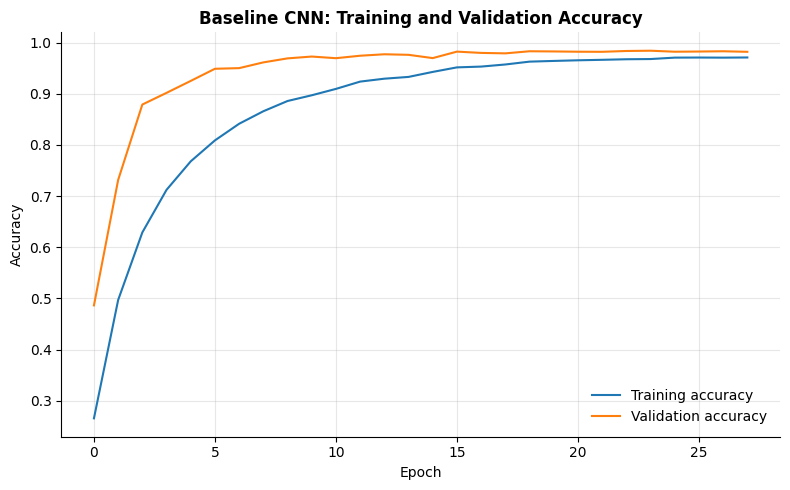

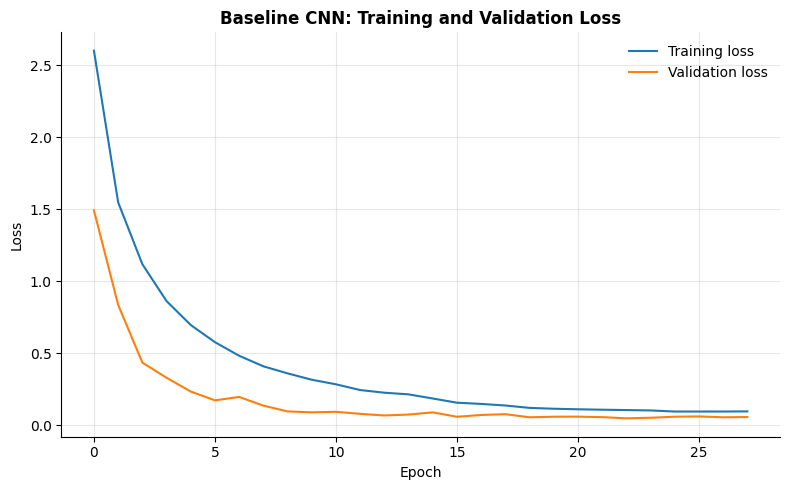

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cnn_history.history["accuracy"], label="Training accuracy")
ax.plot(cnn_history.history["val_accuracy"], label="Validation accuracy")
ax.set_title("Baseline CNN: Training and Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cnn_history.history["loss"], label="Training loss")
ax.plot(cnn_history.history["val_loss"], label="Validation loss")
ax.set_title("Baseline CNN: Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### 2.5 CNN Configuration Summary

In [ ]:
cnn_configuration = pd.DataFrame(
    [
        ("Input shape", str(INPUT_SHAPE)),
        ("Number of output classes", NUM_CLASSES),
        ("Convolutional layers", "3 (32, 64, and 128 filters)"),
        ("Convolution kernel size", "3 × 3"),
        ("Convolution activation", "ReLU"),
        ("Pooling", "Max pooling, 2 × 2"),
        ("Dense layer", "128 units, ReLU"),
        ("Dropout", "0.5"),
        ("Output layer", "43 units, Softmax"),
        ("Loss function", "Sparse categorical cross-entropy"),
        ("Optimizer", "Adam"),
        ("Initial learning rate", INITIAL_LEARNING_RATE),
        ("Batch size", BATCH_SIZE),
        ("Maximum epochs", EPOCHS),
        ("Early stopping", "Monitor validation loss; patience = 5; restore best weights"),
        ("Learning-rate reduction", "Factor = 0.5; patience = 2; minimum = 1e-6"),
    ],
    columns=["Configuration", "Value"],
)
cnn_configuration


,Configuration,Value
0,Input shape,"(64, 64, 3)"
1,Number of output classes,43
2,Convolutional layers,"3 (32, 64, and 128 filters)"
3,Convolution kernel size,3 × 3
4,Convolution activation,ReLU
5,Pooling,"Max pooling, 2 × 2"
6,Dense layer,"128 units, ReLU"
7,Dropout,0.5
8,Output layer,"43 units, Softmax"
9,Loss function,Sparse categorical cross-entropy


## Part 3 : YOLO DETECTION

### 3.1 Extract Dataset and Check GPU

In [ ]:
from pathlib import Path
import torch

# The GTSRB dataset is already extracted in this folder
csv_files = list(Path("/content/gtsrb").rglob("Train.csv"))
print("Train.csv:", csv_files)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Train.csv: [PosixPath('/content/gtsrb/Train.csv')]
GPU available: True
GPU: Tesla T4


### 3.2 Load Annotations and Check Image Paths

In [ ]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/gtsrb")
yolo_train_df = pd.read_csv(data_dir / "Train.csv")
yolo_test_df = pd.read_csv(data_dir / "Test.csv")

print("Training images:", len(yolo_train_df))
print("Testing images:", len(yolo_test_df))
print("Classes:", yolo_train_df["ClassId"].nunique())

missing = sum(
    not (data_dir / path).is_file()
    for path in pd.concat(
        [yolo_train_df["Path"], yolo_test_df["Path"]]
    )
)
print("Missing images:", missing)

display(yolo_train_df.head())

Training images: 39209
Testing images: 12630
Classes: 43
Missing images: 0


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


### 3.3 Visualize Ground Truth Bounding Boxes

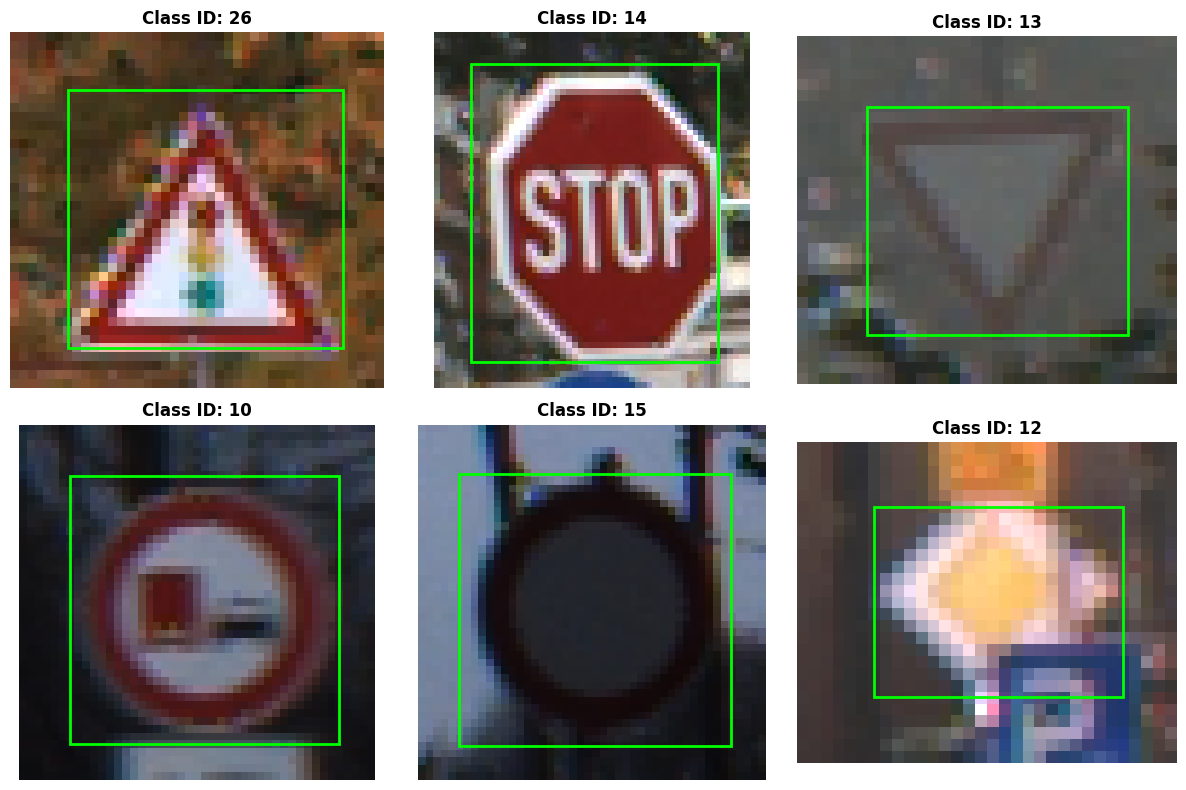

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

samples = yolo_train_df.sample(6, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image = Image.open(data_dir / row["Path"]).convert("RGB")
    ax.imshow(image)

    x1, y1 = row["Roi.X1"], row["Roi.Y1"]
    x2, y2 = row["Roi.X2"], row["Roi.Y2"]

    box = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor="lime", facecolor="none"
    )
    ax.add_patch(box)
    ax.set_title(f'Class ID: {row["ClassId"]}')
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/ground_truth_boxes.png", dpi=200)
plt.show()

### 3.4 Convert Bounding Boxes to YOLO Format

In [ ]:
def convert_to_yolo(row):
    width = row["Width"]
    height = row["Height"]

    x_center = (row["Roi.X1"] + row["Roi.X2"]) / (2 * width)
    y_center = (row["Roi.Y1"] + row["Roi.Y2"]) / (2 * height)
    box_width = (row["Roi.X2"] - row["Roi.X1"]) / width
    box_height = (row["Roi.Y2"] - row["Roi.Y1"]) / height

    return (
        f'{int(row["ClassId"])} '
        f'{x_center:.6f} {y_center:.6f} '
        f'{box_width:.6f} {box_height:.6f}'
    )

example = yolo_train_df.iloc[0]

print("Image:", example["Path"])
print("YOLO label:", convert_to_yolo(example))

Image: Train/20/00020_00000_00000.png
YOLO label: 20 0.500000 0.480769 0.629630 0.576923


### 3.5 Split Training and Validation Data

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Match the image order used in Part 1
yolo_pool = yolo_train_df.sort_values(
    ["ClassId", "Path"]
).reset_index(drop=True)

# Keep images of the same traffic sign together
track_ids = yolo_pool["Path"].apply(
    lambda p: Path(p).stem.rsplit("_", 1)[0]
)

splitter = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_pos, val_pos = next(
    splitter.split(
        yolo_pool,
        yolo_pool["ClassId"],
        groups=track_ids
    )
)

yolo_train_split = yolo_pool.iloc[train_pos].copy()
yolo_val_split = yolo_pool.iloc[val_pos].copy()

assert not set(track_ids.iloc[train_pos]) & set(
    track_ids.iloc[val_pos]
)

print("Training images:", len(yolo_train_split))
print("Validation images:", len(yolo_val_split))
print("Testing images:", len(yolo_test_df))
print("Training classes:", yolo_train_split["ClassId"].nunique())
print("Validation classes:", yolo_val_split["ClassId"].nunique())
print("No track overlap between training and validation.")

Training images: 33599
Validation images: 5610
Testing images: 12630
Training classes: 43
Validation classes: 41
No track overlap between training and validation.


### 3.6 Create YOLO Image and Label Files

In [ ]:
import shutil

yolo_dir = Path("/content/gtsrb_yolo")

splits = {
    "train": yolo_train_split,
    "val": yolo_val_split,
    "test": yolo_test_df
}

for split_name, dataframe in splits.items():
    image_dir = yolo_dir / "images" / split_name
    label_dir = yolo_dir / "labels" / split_name

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for _, row in dataframe.iterrows():
        source = data_dir / row["Path"]

        shutil.copy2(source, image_dir / source.name)

        label_file = label_dir / f"{source.stem}.txt"
        label_file.write_text(
            convert_to_yolo(row) + "\n",
            encoding="utf-8"
        )

    print(
        f"{split_name}: "
        f"{len(list(image_dir.glob('*.png')))} images, "
        f"{len(list(label_dir.glob('*.txt')))} labels"
    )

train: 33599 images, 33599 labels
val: 5610 images, 5610 labels
test: 12630 images, 12630 labels


### 3.7 Create Dataset Configuration

In [ ]:
import yaml

yolo_class_names = [
    "Speed limit (20km/h)", "Speed limit (30km/h)",
    "Speed limit (50km/h)", "Speed limit (60km/h)",
    "Speed limit (70km/h)", "Speed limit (80km/h)",
    "End of speed limit (80km/h)", "Speed limit (100km/h)",
    "Speed limit (120km/h)", "No passing",
    "No passing for vehicles over 3.5t",
    "Right-of-way at next intersection", "Priority road",
    "Yield", "Stop", "No vehicles",
    "Vehicles over 3.5t prohibited", "No entry",
    "General caution", "Dangerous curve to the left",
    "Dangerous curve to the right", "Double curve",
    "Bumpy road", "Slippery road", "Road narrows on the right",
    "Road work", "Traffic signals", "Pedestrians",
    "Children crossing", "Bicycles crossing",
    "Beware of ice/snow", "Wild animals crossing",
    "End of all speed and passing limits",
    "Turn right ahead", "Turn left ahead", "Ahead only",
    "Go straight or right", "Go straight or left",
    "Keep right", "Keep left", "Roundabout mandatory",
    "End of no passing",
    "End of no passing by vehicles over 3.5t"
]

config = {
    "path": str(yolo_dir),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": dict(enumerate(yolo_class_names))
}

yaml_path = yolo_dir / "data.yaml"

with open(yaml_path, "w") as file:
    yaml.safe_dump(config, file, sort_keys=False)

print("Configuration saved:", yaml_path)
print("Number of classes:", len(yolo_class_names))

Configuration saved: /content/gtsrb_yolo/data.yaml
Number of classes: 43


### 3.8 Set Up Results Storage

In [ ]:
from pathlib import Path

results_dir = Path("/content/Traffic_Sign_Project/YOLO")
results_dir.mkdir(parents=True, exist_ok=True)

print("Results folder:", results_dir)

Results folder: /content/Traffic_Sign_Project/YOLO


### 3.9 Install and Load YOLO Model

In [ ]:
%pip install -q ultralytics

In [ ]:
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)

yolo_model = YOLO("yolov8n.pt")
yolo_model.info()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.215
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

### 3.10 Train YOLO Model

In [ ]:
yolo_results = yolo_model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=320,
    batch=32,
    device=0,
    workers=2,
    optimizer="AdamW",
    lr0=0.001,
    patience=5,
    fliplr=0.0,
    flipud=0.0,
    seed=42,
    project=str(results_dir),
    name="yolov8n_baseline",
    save=True,
    plots=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gtsrb_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, opset=None, optimize=

### 3.11 Display Training Curves

Best model saved: True


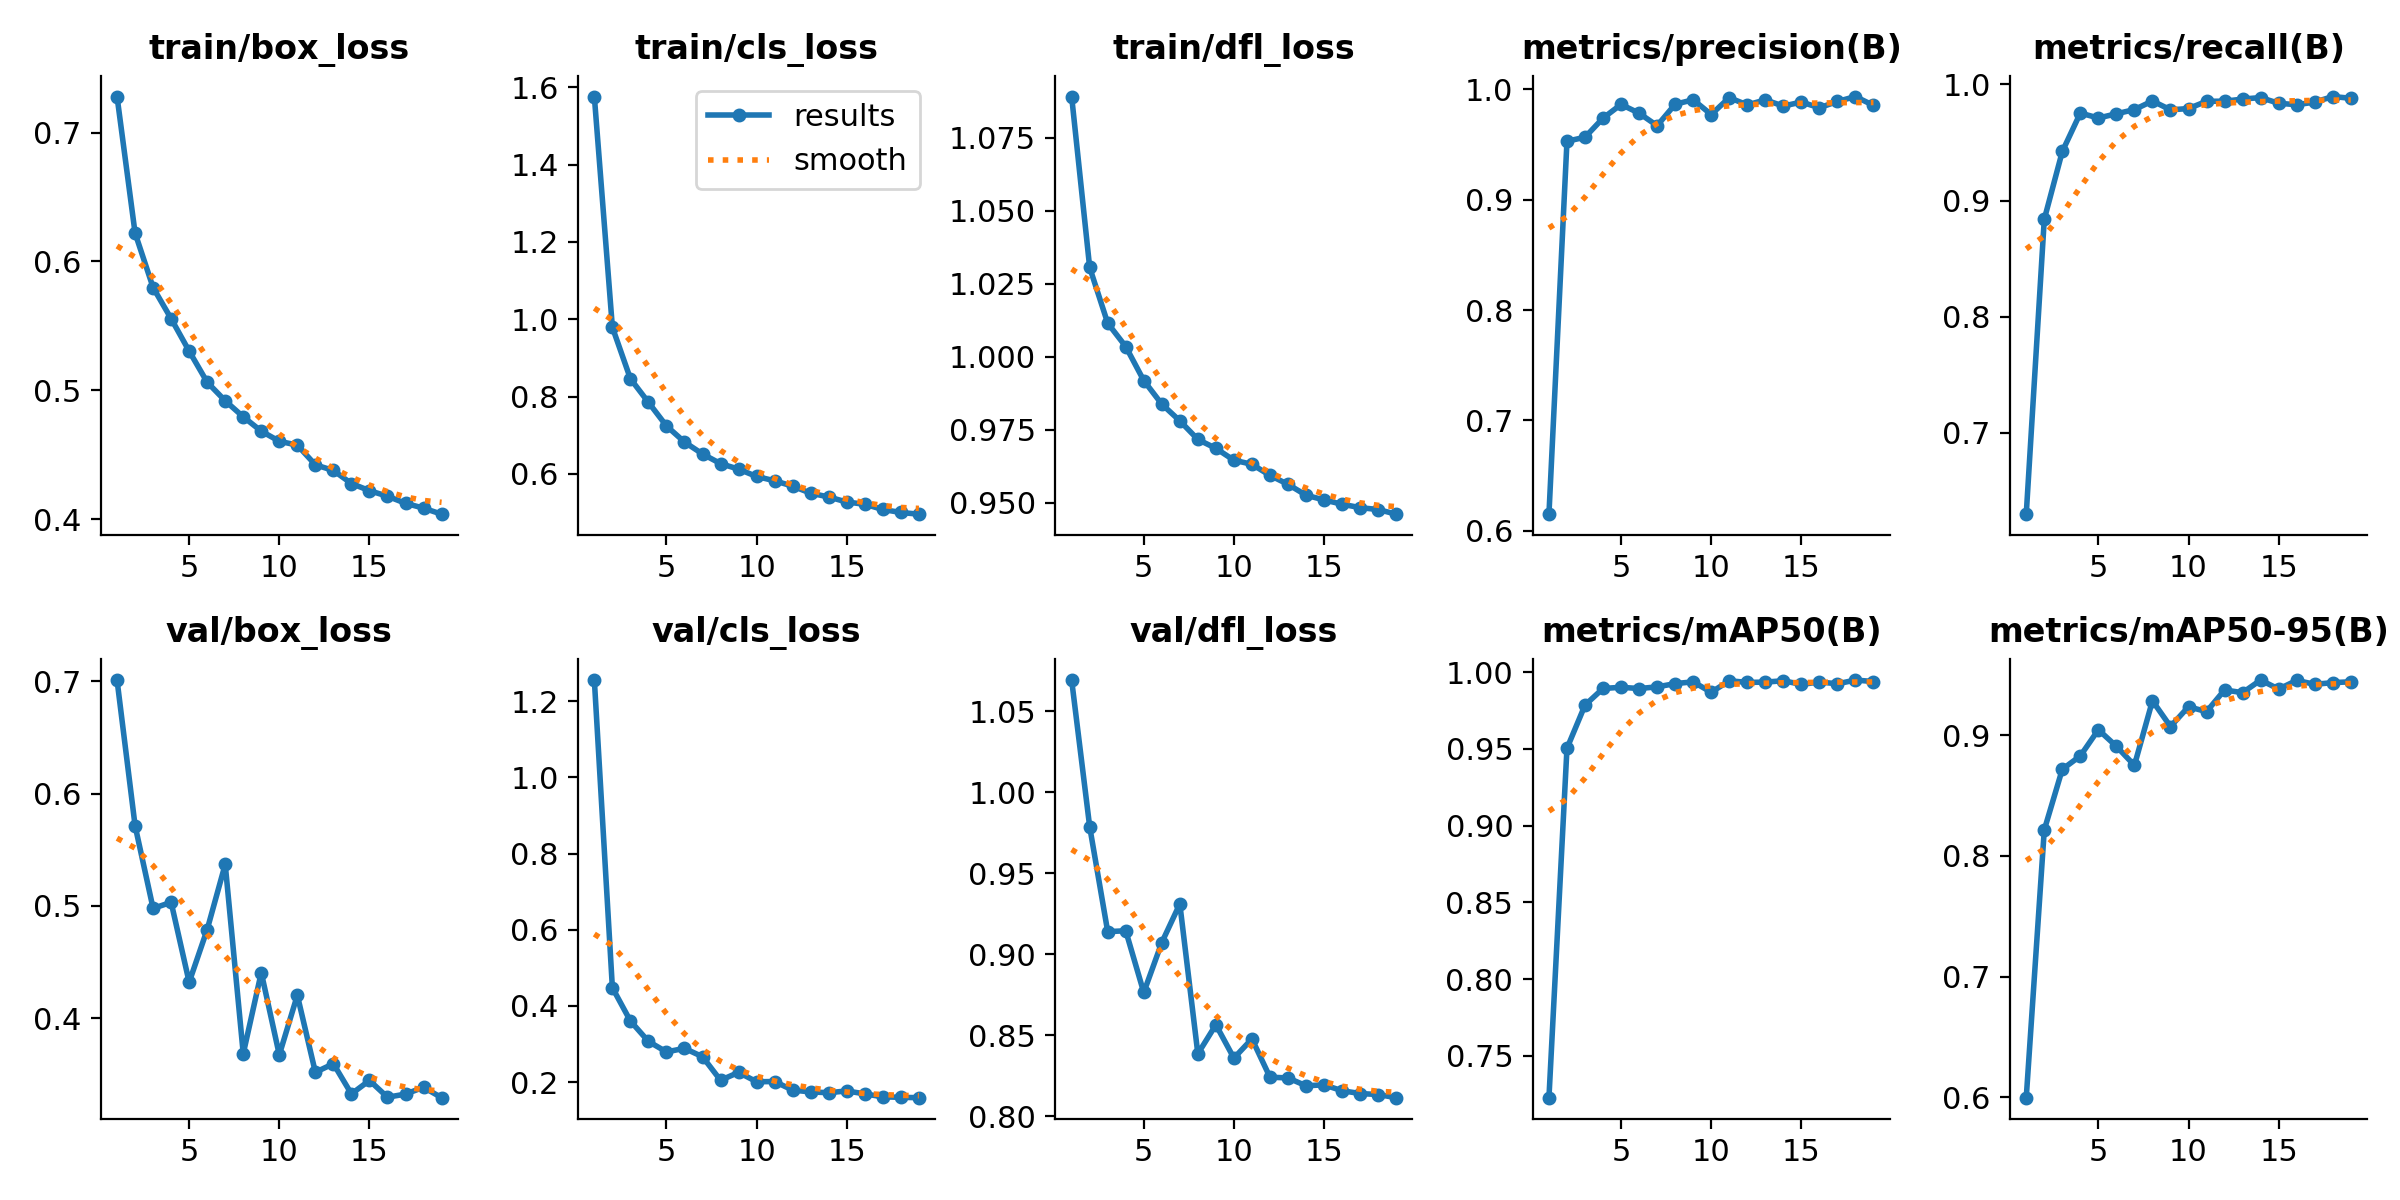

In [ ]:
from IPython.display import Image, display

run_dir = results_dir / "yolov8n_baseline"
best_model_path = run_dir / "weights" / "best.pt"

print("Best model saved:", best_model_path.is_file())
display(Image(filename=str(run_dir / "results.png")))

### 3.12 Predict on Sample Test Images

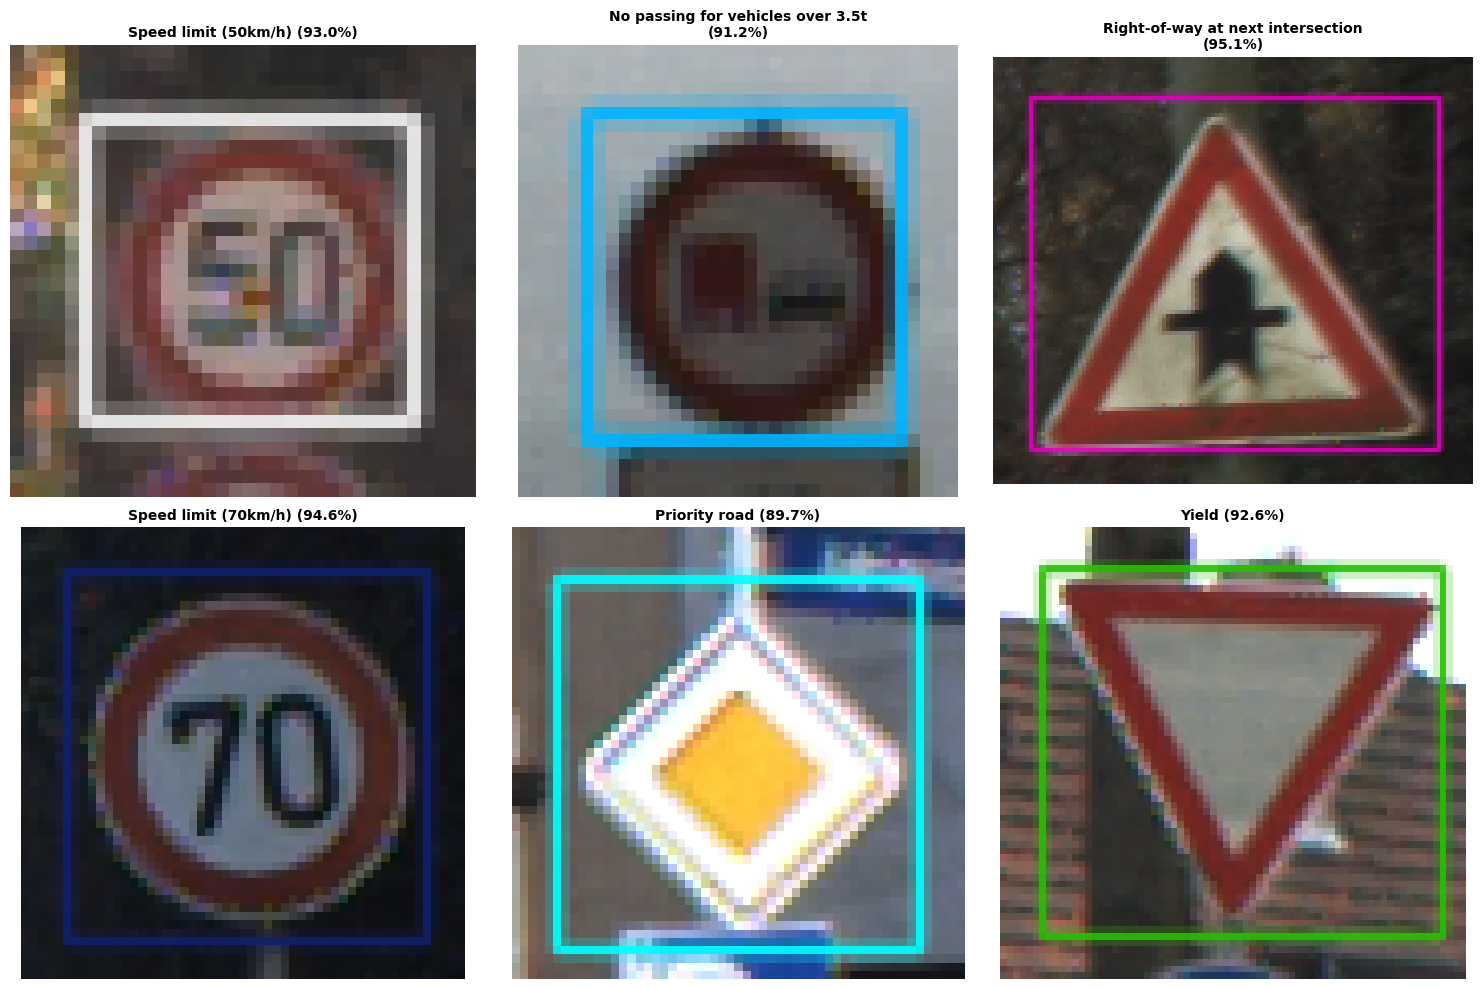

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import textwrap

best_yolo = YOLO(str(best_model_path))

test_samples = yolo_test_df.sample(6, random_state=42)
image_paths = [
    str(data_dir / path) for path in test_samples["Path"]
]

predictions = best_yolo.predict(
    source=image_paths,
    imgsz=320,
    conf=0.25,
    device=0,
    verbose=False
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, result in zip(axes.flat, predictions):
    ax.imshow(
    result.plot(labels=False, conf=False, line_width=1)[:, :, ::-1])

    labels = [
        f"{result.names[int(box.cls.item())]} "
        f"({box.conf.item():.1%})"
        for box in result.boxes
    ]

    title = "\n".join(labels) if labels else "No detection"
    ax.set_title(textwrap.fill(title, width=35), fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "test_predictions.png", dpi=200)
plt.show()

### 3.13 Save Files for Evaluation

In [ ]:
import shutil

shutil.copy2(yaml_path, run_dir / "data.yaml")
shutil.copy2(
    "/content/ground_truth_boxes.png",
    run_dir / "ground_truth_boxes.png"
)

yolo_train_split.to_csv(run_dir / "train_split.csv", index=False)
yolo_val_split.to_csv(run_dir / "val_split.csv", index=False)
yolo_test_df.to_csv(run_dir / "test_split.csv", index=False)

(run_dir / "ultralytics_version.txt").write_text(
    ultralytics.__version__, encoding="utf-8"
)

print("Files saved to:", run_dir)
print("Best model exists:", (run_dir / "weights" / "best.pt").is_file())

Files saved to: /content/Traffic_Sign_Project/YOLO/yolov8n_baseline
Best model exists: True


## Part 4 : EVALUATION & METRICS

## 4.1 CNN Evaluation Metrics and Classification Report

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

# Evaluate the trained CNN on the official test dataset
test_results = cnn_model.evaluate(test_ds, verbose=1, return_dict=True)

# Get true labels and CNN predictions
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])

if y_true.ndim > 1:  # In case labels are one-hot encoded
    y_true = np.argmax(y_true, axis=1)

y_probabilities = cnn_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_probabilities, axis=1)

# Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

# Display final CNN metrics
cnn_metrics_table = pd.DataFrame({
    "Metric": ["Test Loss", "Test Accuracy", "Precision (Weighted)", "Recall (Weighted)", "F1-Score (Weighted)"],
    "Score": [
        test_results["loss"],
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(cnn_metrics_table.style.format({"Score": "{:.4f}"}))

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, zero_division=0))

198/198 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.9827 - loss: 0.0672
198/198 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step


,Metric,Score
0,Test Loss,0.0672
1,Test Accuracy,0.9827
2,Precision (Weighted),0.9835
3,Recall (Weighted),0.9827
4,F1-Score (Weighted),0.9824



Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       0.98      1.00      0.99       720
           2       1.00      0.99      1.00       750
           3       1.00      0.92      0.96       450
           4       1.00      0.98      0.99       660
           5       0.93      0.99      0.96       630
           6       1.00      0.99      1.00       150
           7       1.00      1.00      1.00       450
           8       0.98      0.98      0.98       450
           9       1.00      0.99      0.99       480
          10       1.00      1.00      1.00       660
          11       0.92      0.99      0.95       420
          12       1.00      0.99      0.99       690
          13       1.00      1.00      1.00       720
          14       1.00      1.00      1.00       270
          15       0.97      1.00      0.98       210
          16       1.00      1.00      1.00       150
  

## 4.2 CNN Confusion Matrix

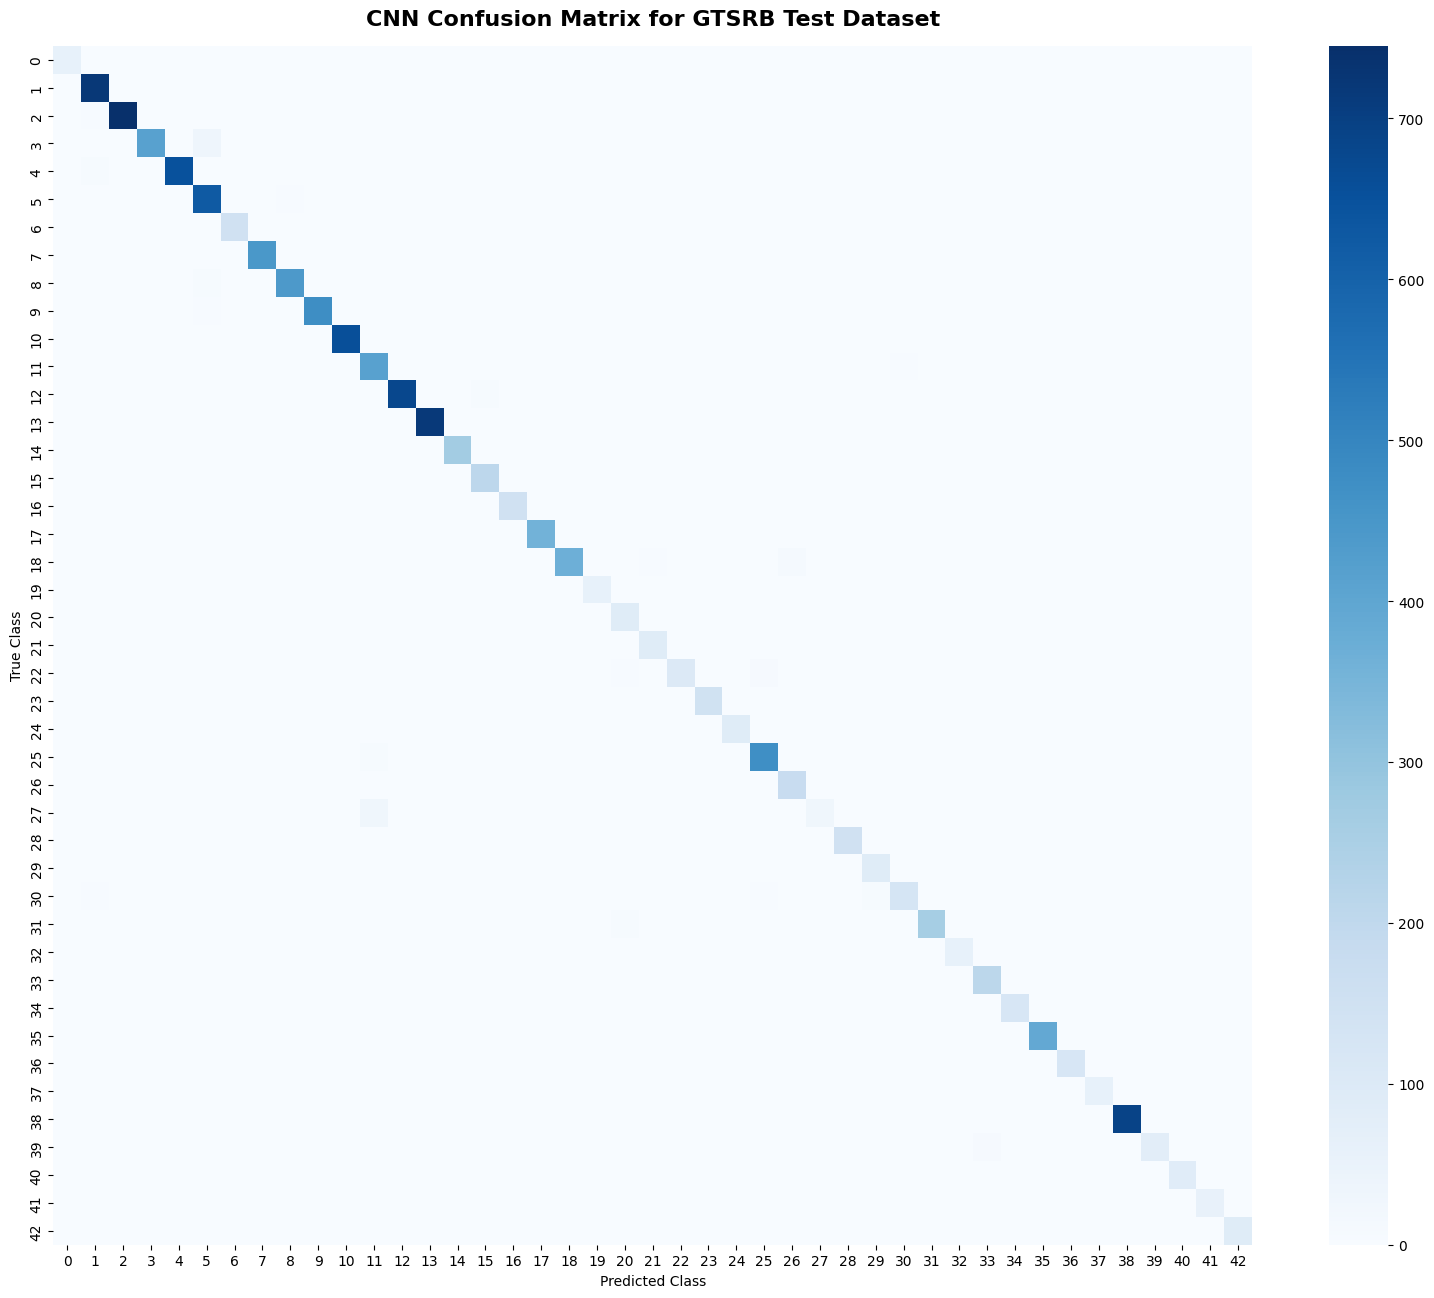

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    cmap="Blues",
    cbar=True,
    square=True,
    xticklabels=np.arange(NUM_CLASSES),
    yticklabels=np.arange(NUM_CLASSES)
)

plt.title("CNN Confusion Matrix for GTSRB Test Dataset", fontsize=16, pad=15)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

## 4.3 CNN Training and Validation Curves

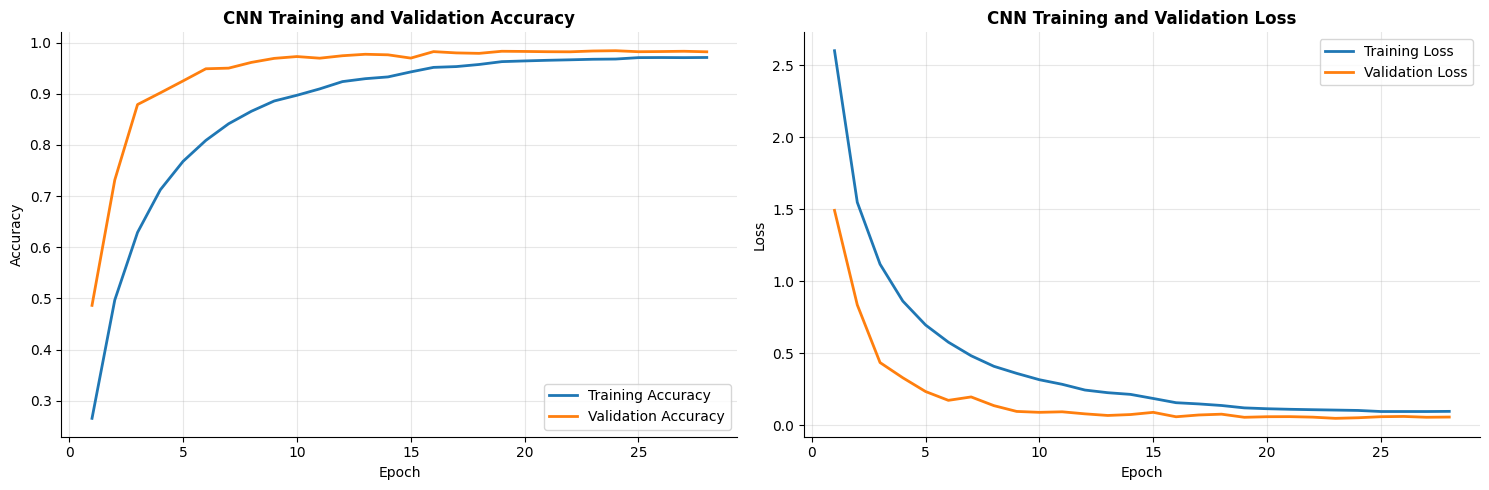

In [ ]:
history_data = cnn_history.history
epochs_ran = range(1, len(history_data["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy curves
axes[0].plot(epochs_ran, history_data["accuracy"], label="Training Accuracy", linewidth=2)
axes[0].plot(epochs_ran, history_data["val_accuracy"], label="Validation Accuracy", linewidth=2)
axes[0].set_title("CNN Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss curves
axes[1].plot(epochs_ran, history_data["loss"], label="Training Loss", linewidth=2)
axes[1].plot(epochs_ran, history_data["val_loss"], label="Validation Loss", linewidth=2)
axes[1].set_title("CNN Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
cnn_final_results = pd.DataFrame({
    "Metric": [
        "Number of Test Images",
        "Training Epochs Completed",
        "Test Loss",
        "Test Accuracy",
        "Precision (Weighted)",
        "Recall (Weighted)",
        "F1-Score (Weighted)"
    ],
    "Result": [
        len(y_true),
        len(cnn_history.history["loss"]),
        test_results["loss"],
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(cnn_final_results.style.format({
    "Result": lambda value: f"{value:.4f}" if isinstance(value, float) else str(value)
}))

,Metric,Result
0,Number of Test Images,12630.0000
1,Training Epochs Completed,28.0000
2,Test Loss,0.0672
3,Test Accuracy,0.9827
4,Precision (Weighted),0.9835
5,Recall (Weighted),0.9827
6,F1-Score (Weighted),0.9824


## 4.4 YOLO Evaluation and CNN–YOLO Comparison

,Metric,Result
0,Validation Images,5610.0000
1,Epochs Completed,19.0000
2,Best Epoch,14.0000
3,Precision,0.9840
4,Recall,0.9890
5,mAP@50,0.9940
6,mAP@50–95,0.9460


,Measure,CNN,YOLOv8n
0,Task,Traffic-sign classification,Traffic-sign detection
1,Evaluation Images,12630,5610
2,Precision,0.9835,0.9840
3,Recall,0.9827,0.9890
4,Main Performance Metric,Accuracy = 0.9827; F1-score = 0.9824,mAP@50 = 0.9940; mAP@50–95 = 0.9460


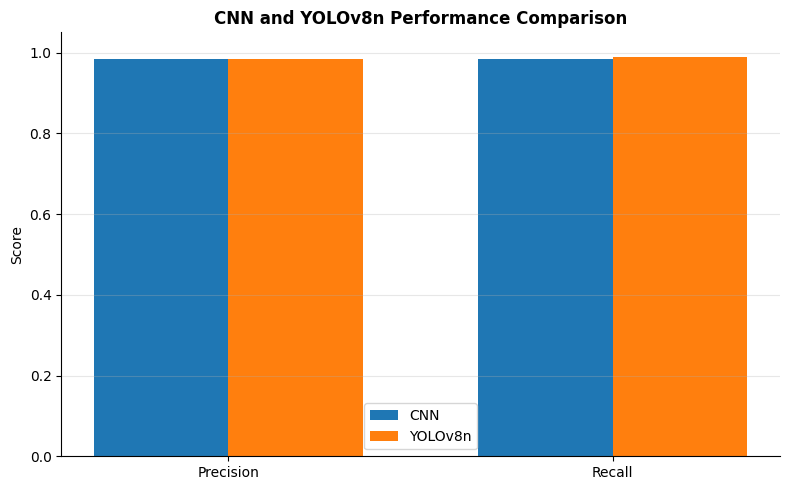

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Final YOLO validation results from best.pt
yolo_precision = 0.984
yolo_recall = 0.989
yolo_map50 = 0.994
yolo_map50_95 = 0.946
yolo_epochs_completed = 19
yolo_best_epoch = 14

# YOLO results table
yolo_metrics_table = pd.DataFrame({
    "Metric": [
        "Validation Images",
        "Epochs Completed",
        "Best Epoch",
        "Precision",
        "Recall",
        "mAP@50",
        "mAP@50–95"
    ],
    "Result": [
        5610,
        yolo_epochs_completed,
        yolo_best_epoch,
        yolo_precision,
        yolo_recall,
        yolo_map50,
        yolo_map50_95
    ]
})

display(yolo_metrics_table.style.format({
    "Result": lambda value: f"{value:.4f}" if isinstance(value, float) else str(value)
}))

# CNN–YOLO comparison table
comparison_table = pd.DataFrame({
    "Measure": ["Task", "Evaluation Images", "Precision", "Recall", "Main Performance Metric"],
    "CNN": [
        "Traffic-sign classification",
        len(y_true),
        f"{precision:.4f}",
        f"{recall:.4f}",
        f"Accuracy = {accuracy:.4f}; F1-score = {f1:.4f}"
    ],
    "YOLOv8n": [
        "Traffic-sign detection",
        5610,
        f"{yolo_precision:.4f}",
        f"{yolo_recall:.4f}",
        f"mAP@50 = {yolo_map50:.4f}; mAP@50–95 = {yolo_map50_95:.4f}"
    ]
})

display(comparison_table)

# Comparison plot for the common metrics
metrics = ["Precision", "Recall"]
cnn_scores = [precision, recall]
yolo_scores = [yolo_precision, yolo_recall]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, cnn_scores, width, label="CNN")
plt.bar(x + width / 2, yolo_scores, width, label="YOLOv8n")

plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("CNN and YOLOv8n Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Part 5 : OPTIMIZATION & HYPERPARAMETER TUNING

## 5.0 Restore the Baseline Model and Prepare a RAM-Efficient Data Pipeline

This section restores the saved baseline CNN and its training history from Google Drive. It rebuilds the same GTSRB train/validation/test split used in Part 1, but loads and resizes images in batches from disk instead of keeping the full image arrays in RAM.

**Important:** The original Parts 1–4 are preserved. This section does not retrain or modify the baseline CNN or YOLO models. The official test set is reserved for the final evaluation only.

In [1]:
# ==========================================
# 5.0 Restore baseline artifacts and prepare data
# ==========================================

import os
import gc
import json
import time
import zipfile
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Mount Google Drive only if it is not already mounted.
if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive")
BACKUP_DIR = DRIVE_ROOT / "Traffic_Sign_Project_Backup"
OPTIMIZATION_DIR = DRIVE_ROOT / "Traffic_Sign_Project_Optimization_v2"
OPTIMIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Restore the original baseline model and training history.
BASELINE_MODEL_PATH = BACKUP_DIR / "baseline_cnn_gtsrb.keras"
BASELINE_HISTORY_PATH = BACKUP_DIR / "baseline_cnn_training_history.csv"

if not BASELINE_MODEL_PATH.exists():
    raise FileNotFoundError(f"Baseline CNN not found: {BASELINE_MODEL_PATH}")
if not BASELINE_HISTORY_PATH.exists():
    raise FileNotFoundError(f"Baseline history not found: {BASELINE_HISTORY_PATH}")

baseline_model = keras.models.load_model(
    BASELINE_MODEL_PATH,
    compile=False
)
baseline_history_df = pd.read_csv(BASELINE_HISTORY_PATH)

# The saved CSV includes an epoch column. Keep the metric columns unchanged.
if "epoch" in baseline_history_df.columns:
    baseline_history_df = baseline_history_df.drop(columns=["epoch"])

required_history_columns = {
    "accuracy", "loss", "val_accuracy", "val_loss"
}
missing_history = required_history_columns - set(baseline_history_df.columns)
if missing_history:
    raise ValueError(f"Missing baseline history columns: {missing_history}")

print("Baseline CNN restored.")
print("Input shape:", baseline_model.input_shape)
print("Output shape:", baseline_model.output_shape)
print("Recorded epochs:", len(baseline_history_df))
print("Best baseline validation accuracy:",
      round(float(baseline_history_df["val_accuracy"].max()), 6))
print("Minimum baseline validation loss:",
      round(float(baseline_history_df["val_loss"].min()), 6))

# Locate the same GTSRB dataset used in Part 1.
DATASET_ROOT = Path("/content/gtsrb")
TRAIN_DIR = DATASET_ROOT / "Train"
TEST_CSV = DATASET_ROOT / "Test.csv"

if not TRAIN_DIR.exists() or not TEST_CSV.exists():
    zip_path = Path("/content/gtsrb.zip")
    dataset_url = (
        "https://www.kaggle.com/api/v1/datasets/download/"
        "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
    )
    print("GTSRB files are not present. Downloading the dataset...")
    subprocess.run(
        ["wget", "-q", "--show-progress", dataset_url, "-O", str(zip_path)],
        check=True
    )
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATASET_ROOT)

if not TRAIN_DIR.exists() or not TEST_CSV.exists():
    raise FileNotFoundError(
        "GTSRB dataset structure is incomplete. Expected Train/ and Test.csv."
    )

# Rebuild the file list in the same order and format as Part 1.
class_folders = sorted(
    [
        folder for folder in TRAIN_DIR.iterdir()
        if folder.is_dir() and folder.name.isdigit()
    ],
    key=lambda folder: int(folder.name)
)

train_records = [
    {"path": image_path, "class_id": int(folder.name), "source": "train"}
    for folder in class_folders
    for image_path in sorted(folder.glob("*.png"))
]

test_csv_df = pd.read_csv(TEST_CSV)
test_records = [
    {
        "path": DATASET_ROOT / row.Path,
        "class_id": int(row.ClassId),
        "source": "test"
    }
    for row in test_csv_df.itertuples(index=False)
]

all_records_df = pd.DataFrame(train_records + test_records)

# Match Part 1 by excluding unreadable/corrupt images.
valid_records = []
excluded_count = 0

for record in all_records_df.to_dict("records"):
    try:
        with Image.open(record["path"]) as image:
            image.load()
        valid_records.append(record)
    except Exception:
        excluded_count += 1

data_df = pd.DataFrame(valid_records).reset_index(drop=True)

# Recreate the exact Part 1 split:
# official Test set remains Test; official Train is split 85/15
# using StratifiedGroupKFold and the same track-ID rule.
y_all = data_df["class_id"].to_numpy(dtype=np.int32)
track_ids = data_df["path"].apply(
    lambda p: Path(p).stem.rsplit("_", 1)[0]
).to_numpy()

is_train = (data_df["source"] == "train").to_numpy()
train_pool_idx = np.where(is_train)[0]
test_idx = np.where(~is_train)[0]

VALIDATION_SPLIT = 0.15
splitter = StratifiedGroupKFold(
    n_splits=round(1 / VALIDATION_SPLIT),
    shuffle=True,
    random_state=SEED
)

train_pos, val_pos = next(
    splitter.split(
        train_pool_idx,
        y_all[train_pool_idx],
        track_ids[train_pool_idx]
    )
)

train_idx = train_pool_idx[train_pos]
val_idx = train_pool_idx[val_pos]

# Confirm that the reconstructed split has no image or track leakage.
assert not set(train_idx) & set(val_idx)
assert not set(train_idx) & set(test_idx)
assert not set(val_idx) & set(test_idx)
assert not (
    set(track_ids[train_idx]) & set(track_ids[val_idx])
)

train_paths = data_df.iloc[train_idx]["path"].astype(str).to_numpy()
train_labels = y_all[train_idx]

val_paths = data_df.iloc[val_idx]["path"].astype(str).to_numpy()
val_labels = y_all[val_idx]

test_paths = data_df.iloc[test_idx]["path"].astype(str).to_numpy()
test_labels = y_all[test_idx]

# Match the original Part 1 training order exactly: apply one full
# random permutation to training paths and labels before the tf.data
# shuffle buffer is applied. This avoids long class-ordered sequences.
train_order = np.random.default_rng(SEED).permutation(len(train_paths))
train_paths = train_paths[train_order]
train_labels = train_labels[train_order]

INPUT_SHAPE = (64, 64, 3)
NUM_CLASSES = 43
BASELINE_BATCH_SIZE = 64

print("\nDataset reconstructed without loading all images into RAM.")
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))
print("Corrupt images excluded:", excluded_count)
print("Full training-path permutation: applied (seed=42)")
print("Input shape:", INPUT_SHAPE)
print("Number of classes:", NUM_CLASSES)

Mounted at /content/drive
Baseline CNN restored.
Input shape: (None, 64, 64, 3)
Output shape: (None, 43)
Recorded epochs: 28
Best baseline validation accuracy: 0.984135
Minimum baseline validation loss: 0.049462
GTSRB files are not present. Downloading the dataset...

Dataset reconstructed without loading all images into RAM.
Training images: 33599
Validation images: 5610
Test images: 12630
Corrupt images excluded: 0
Full training-path permutation: applied (seed=42)
Input shape: (64, 64, 3)
Number of classes: 43


## 5.1 Define Hyperparameters and Experiment Configurations

The experiments use a one-factor-at-a-time approach: one hyperparameter is changed while the remaining baseline settings are held constant. The original baseline configuration is included for comparison.

The original CNN uses three convolutional layers with 32, 64, and 128 filters, a Dense layer with 128 units, Dropout 0.5, Adam with initial learning rate 0.001, and a maximum of 30 epochs.

In [2]:
# ==========================================
# 5.1 Define hyperparameter configurations
# ==========================================

BASELINE_CONFIG = {
    "Experiment": "Baseline CNN",
    "Learning Rate": 0.001,
    "Batch Size": 64,
    "Optimizer": "Adam",
    "Dropout": 0.5,
    "Filters": [32, 64, 128],
    "Max Epochs": 30
}

# Each experiment changes one main hyperparameter group.
# The baseline settings are retained for all other parameters.
TUNING_CONFIGS = [
    {
        "Experiment": "Learning Rate 0.0005",
        "Learning Rate": 0.0005,
        "Batch Size": 64,
        "Optimizer": "Adam",
        "Dropout": 0.5,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    },
    {
        "Experiment": "Learning Rate 0.0001",
        "Learning Rate": 0.0001,
        "Batch Size": 64,
        "Optimizer": "Adam",
        "Dropout": 0.5,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    },
    {
        "Experiment": "Batch Size 32",
        "Learning Rate": 0.001,
        "Batch Size": 32,
        "Optimizer": "Adam",
        "Dropout": 0.5,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    },
    {
        "Experiment": "Batch Size 128",
        "Learning Rate": 0.001,
        "Batch Size": 128,
        "Optimizer": "Adam",
        "Dropout": 0.5,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    },
    {
        "Experiment": "SGD Optimizer",
        "Learning Rate": 0.01,
        "Batch Size": 64,
        "Optimizer": "SGD",
        "Dropout": 0.5,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    },
    {
        "Experiment": "10 Epochs",
        "Learning Rate": 0.001,
        "Batch Size": 64,
        "Optimizer": "Adam",
        "Dropout": 0.5,
        "Filters": [32, 64, 128],
        "Max Epochs": 10
    },
    {
        "Experiment": "20 Epochs",
        "Learning Rate": 0.001,
        "Batch Size": 64,
        "Optimizer": "Adam",
        "Dropout": 0.5,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    },
    {
        "Experiment": "Smaller CNN Filters",
        "Learning Rate": 0.001,
        "Batch Size": 64,
        "Optimizer": "Adam",
        "Dropout": 0.5,
        "Filters": [16, 32, 64],
        "Max Epochs": 20
    },
    {
        "Experiment": "Dropout 0.3",
        "Learning Rate": 0.001,
        "Batch Size": 64,
        "Optimizer": "Adam",
        "Dropout": 0.3,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    },
    {
        "Experiment": "Dropout 0.7",
        "Learning Rate": 0.001,
        "Batch Size": 64,
        "Optimizer": "Adam",
        "Dropout": 0.7,
        "Filters": [32, 64, 128],
        "Max Epochs": 20
    }
]

print("Baseline configuration:")
display(pd.DataFrame([BASELINE_CONFIG]))

print("\nPlanned tuning experiments:", len(TUNING_CONFIGS))
display(pd.DataFrame(TUNING_CONFIGS))

Baseline configuration:


,Experiment,Learning Rate,Batch Size,Optimizer,Dropout,Filters,Max Epochs
0,Baseline CNN,0.001,64,Adam,0.5,"[32, 64, 128]",30



Planned tuning experiments: 10


,Experiment,Learning Rate,Batch Size,Optimizer,Dropout,Filters,Max Epochs
0,Learning Rate 0.0005,0.0005,64,Adam,0.5,"[32, 64, 128]",20
1,Learning Rate 0.0001,0.0001,64,Adam,0.5,"[32, 64, 128]",20
2,Batch Size 32,0.0010,32,Adam,0.5,"[32, 64, 128]",20
3,Batch Size 128,0.0010,128,Adam,0.5,"[32, 64, 128]",20
4,SGD Optimizer,0.0100,64,SGD,0.5,"[32, 64, 128]",20
5,10 Epochs,0.0010,64,Adam,0.5,"[32, 64, 128]",10
6,20 Epochs,0.0010,64,Adam,0.5,"[32, 64, 128]",20
7,Smaller CNN Filters,0.0010,64,Adam,0.5,"[16, 32, 64]",20
8,Dropout 0.3,0.0010,64,Adam,0.3,"[32, 64, 128]",20
9,Dropout 0.7,0.0010,64,Adam,0.7,"[32, 64, 128]",20


## 5.2 Build the CNN and Create a RAM-Efficient Input Pipeline

The CNN architecture follows the original baseline architecture. Only the requested hyperparameters are changed between experiments.

Images are read from disk in batches, resized to 64 × 64, converted to RGB, and normalized to [0, 1]. The original augmentation operations are applied to the training set only. Validation and test images are not augmented.

In [3]:
# ==========================================
# 5.2 RAM-efficient data pipeline and CNN
# ==========================================

# Match the augmentation settings in Part 1.
data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(
            factor=10 / 360,
            fill_mode="nearest",
            seed=SEED
        ),
        layers.RandomZoom(
            height_factor=0.10,
            fill_mode="nearest",
            seed=SEED
        ),
        layers.RandomTranslation(
            height_factor=0.10,
            width_factor=0.10,
            fill_mode="nearest",
            seed=SEED
        ),
        layers.RandomBrightness(
            factor=0.20,
            value_range=(0.0, 1.0),
            seed=SEED
        ),
    ],
    name="data_augmentation"
)

def _read_resize_image(path_value):
    """Use PIL resizing to match the preprocessing method in Part 1."""
    if isinstance(path_value, np.ndarray):
        path_value = path_value.item()
    if isinstance(path_value, bytes):
        path_value = path_value.decode("utf-8")

    with Image.open(str(path_value)) as image:
        image = image.convert("RGB").resize((64, 64))
        return np.asarray(image, dtype=np.uint8)


def _load_image_tensor(path, label):
    image = tf.numpy_function(
        _read_resize_image,
        [path],
        Tout=tf.uint8
    )
    image.set_shape([64, 64, 3])
    image = tf.image.convert_image_dtype(image, tf.float32)
    label = tf.cast(label, tf.int32)
    return image, label


def make_path_dataset(paths, labels, batch_size=64, training=False):
    """
    Read image files from disk in small batches.
    No full X_train/X_val/X_test arrays are created in RAM.
    """
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths.astype(str), labels.astype(np.int32))
    )

    if training:
        # Paths/labels were already fully permuted in Section 5.0, matching
        # Part 1. Keep the original 2,048-item shuffle buffer as well.
        dataset = dataset.shuffle(
            buffer_size=min(len(paths), 2048),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        _load_image_tensor,
        num_parallel_calls=2,
        deterministic=not training
    )

    dataset = dataset.batch(batch_size, drop_remainder=False)

    if training:
        dataset = dataset.map(
            lambda images, labels: (
                data_augmentation(images, training=True),
                labels
            ),
            num_parallel_calls=1
        )

    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 1
    dataset = dataset.with_options(options)

    return dataset.prefetch(1)


def build_tuned_cnn(config):
    """Build the same CNN structure used by the original baseline."""
    model = keras.Sequential(
        [
            keras.Input(shape=INPUT_SHAPE),

            layers.Conv2D(
                config["Filters"][0],
                kernel_size=3,
                padding="same",
                activation="relu"
            ),
            layers.MaxPooling2D(pool_size=2),

            layers.Conv2D(
                config["Filters"][1],
                kernel_size=3,
                padding="same",
                activation="relu"
            ),
            layers.MaxPooling2D(pool_size=2),

            layers.Conv2D(
                config["Filters"][2],
                kernel_size=3,
                padding="same",
                activation="relu"
            ),
            layers.MaxPooling2D(pool_size=2),

            layers.Flatten(),
            layers.Dense(128, activation="relu"),
            layers.Dropout(config["Dropout"]),
            layers.Dense(NUM_CLASSES, activation="softmax")
        ],
        name="tuned_cnn"
    )
    return model


def create_optimizer(config):
    learning_rate = config["Learning Rate"]

    if config["Optimizer"] == "Adam":
        return keras.optimizers.Adam(
            learning_rate=learning_rate
        )
    elif config["Optimizer"] == "SGD":
        return keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )
    else:
        raise ValueError(
            f"Unsupported optimizer: {config['Optimizer']}"
        )


# Quick check: read one small batch only.
check_ds = make_path_dataset(
    train_paths[:8],
    train_labels[:8],
    batch_size=4,
    training=False
)
check_images, check_labels = next(iter(check_ds))

print("Image batch shape:", check_images.shape)
print("Label batch shape:", check_labels.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(check_images)),
    "to",
    float(tf.reduce_max(check_images))
)

Image batch shape: (4, 64, 64, 3)
Label batch shape: (4,)
Pixel range: 0.062745101749897 to 1.0


## 5.3 Run Hyperparameter Experiments

Each completed experiment is immediately saved to Google Drive. If the runtime stops, rerunning this cell will skip experiments already recorded in the results CSV and continue with the remaining configurations.

The baseline row is taken from the saved original training history; the baseline model is not retrained here.

In [4]:
# ==========================================
# 5.3 Run and record all experiments
# ==========================================

RESULTS_CSV = OPTIMIZATION_DIR / "hyperparameter_results.csv"
HISTORY_DIR = OPTIMIZATION_DIR / "experiment_histories"
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

# Add the original baseline results from its saved history.
baseline_best_loss_idx = int(
    baseline_history_df["val_loss"].idxmin()
)
baseline_best_acc_idx = int(
    baseline_history_df["val_accuracy"].idxmax()
)

baseline_row = {
    "Experiment": "Baseline CNN",
    "Learning Rate": 0.001,
    "Batch Size": 64,
    "Optimizer": "Adam",
    "Dropout": 0.5,
    "Filters": "[32, 64, 128]",
    "Max Epochs": 30,
    "Epochs Completed": len(baseline_history_df),
    "Best Loss Epoch": baseline_best_loss_idx + 1,
    "Best Accuracy Epoch": baseline_best_acc_idx + 1,
    "Best Validation Accuracy": float(
        baseline_history_df["val_accuracy"].max()
    ),
    "Best Validation Loss": float(
        baseline_history_df["val_loss"].min()
    ),
    "Training Time (seconds)": np.nan
}

if RESULTS_CSV.exists():
    results_df = pd.read_csv(RESULTS_CSV)
    if "Baseline CNN" not in results_df["Experiment"].values:
        results_df = pd.concat(
            [pd.DataFrame([baseline_row]), results_df],
            ignore_index=True
        )
else:
    results_df = pd.DataFrame([baseline_row])
    results_df.to_csv(RESULTS_CSV, index=False)

completed_experiments = set(results_df["Experiment"].astype(str))

print("Already completed:", sorted(completed_experiments))
print("Experiments remaining:",
      sum(c["Experiment"] not in completed_experiments
          for c in TUNING_CONFIGS))

for config in TUNING_CONFIGS:

    experiment_name = config["Experiment"]

    if experiment_name in completed_experiments:
        print(f"\nSkipping already saved experiment: {experiment_name}")
        continue

    print("\n" + "=" * 65)
    print("Starting:", experiment_name)
    print("=" * 65)

    keras.backend.clear_session()
    gc.collect()

    train_ds = make_path_dataset(
        train_paths,
        train_labels,
        batch_size=config["Batch Size"],
        training=True
    )
    val_ds = make_path_dataset(
        val_paths,
        val_labels,
        batch_size=config["Batch Size"],
        training=False
    )

    model = build_tuned_cnn(config)

    model.compile(
        optimizer=create_optimizer(config),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]

    start_time = time.time()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=config["Max Epochs"],
        callbacks=callbacks,
        verbose=1
    )

    elapsed_seconds = time.time() - start_time
    history_values = history.history

    best_loss_idx = int(np.argmin(history_values["val_loss"]))
    best_acc_idx = int(np.argmax(history_values["val_accuracy"]))

    result_row = {
        "Experiment": experiment_name,
        "Learning Rate": config["Learning Rate"],
        "Batch Size": config["Batch Size"],
        "Optimizer": config["Optimizer"],
        "Dropout": config["Dropout"],
        "Filters": str(config["Filters"]),
        "Max Epochs": config["Max Epochs"],
        "Epochs Completed": len(history_values["loss"]),
        "Best Loss Epoch": best_loss_idx + 1,
        "Best Accuracy Epoch": best_acc_idx + 1,
        "Best Validation Accuracy": float(
            history_values["val_accuracy"][best_acc_idx]
        ),
        "Best Validation Loss": float(
            history_values["val_loss"][best_loss_idx]
        ),
        "Training Time (seconds)": float(elapsed_seconds)
    }

    # Save the history and summary immediately after each experiment.
    safe_name = (
        experiment_name.lower()
        .replace(" ", "_")
        .replace(".", "_")
    )
    pd.DataFrame(history_values).to_csv(
        HISTORY_DIR / f"{safe_name}_history.csv",
        index=False
    )

    results_df = pd.concat(
        [results_df, pd.DataFrame([result_row])],
        ignore_index=True
    )
    results_df.to_csv(RESULTS_CSV, index=False)

    # Ensure the result summary is flushed to Drive before starting
    # the next (potentially long) experiment.
    print("\nSaved:", experiment_name)
    print("Best validation accuracy:",
          round(result_row["Best Validation Accuracy"], 5))
    print("Best validation loss:",
          round(result_row["Best Validation Loss"], 5))
    print("Training time (seconds):",
          round(elapsed_seconds, 1))

    del model, history, train_ds, val_ds
    gc.collect()

print("\nAll configured experiments are completed or already saved.")
display(
    pd.read_csv(RESULTS_CSV).sort_values(
        "Best Validation Loss"
    ).reset_index(drop=True)
)

Already completed: ['Baseline CNN']
Experiments remaining: 10

Starting: Learning Rate 0.0005
Epoch 1/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 93s 156ms/step - accuracy: 0.2544 - loss: 2.7358 - val_accuracy: 0.5082 - val_loss: 1.5954 - learning_rate: 5.0000e-04
Epoch 2/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 106s 106ms/step - accuracy: 0.4870 - loss: 1.6497 - val_accuracy: 0.7180 - val_loss: 0.9194 - learning_rate: 5.0000e-04
Epoch 3/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 84s 109ms/step - accuracy: 0.6231 - loss: 1.1747 - val_accuracy: 0.8394 - val_loss: 0.5090 - learning_rate: 5.0000e-04
Epoch 4/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 83s 110ms/step - accuracy: 0.7104 - loss: 0.9026 - val_accuracy: 0.9052 - val_loss: 0.3510 - learning_rate: 5.0000e-04
Epoch 5/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 58s 110ms/step - accuracy: 0.7674 - loss: 0.7216 - val_accuracy: 0.9273 - val_loss: 0.2652 - learning_rate: 5.0000e-04
Epoch 6/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 82s 110ms/step - accuracy: 0.8067 - loss: 0.6019 - val_accuracy: 0.930

,Experiment,Learning Rate,Batch Size,Optimizer,Dropout,Filters,Max Epochs,Epochs Completed,Best Loss Epoch,Best Accuracy Epoch,Best Validation Accuracy,Best Validation Loss,Training Time (seconds)
0,Baseline CNN,0.0010,64,Adam,0.5,"[32, 64, 128]",30,28,23,24,0.984135,0.049462,NaN
1,Dropout 0.7,0.0010,64,Adam,0.7,"[32, 64, 128]",20,20,18,16,0.981105,0.054239,1347.208821
2,20 Epochs,0.0010,64,Adam,0.5,"[32, 64, 128]",20,20,18,18,0.985027,0.068949,1345.805191
3,Batch Size 128,0.0010,128,Adam,0.5,"[32, 64, 128]",20,20,19,19,0.979144,0.069523,1206.940793
4,Smaller CNN Filters,0.0010,64,Adam,0.5,"[16, 32, 64]",20,20,19,17,0.978788,0.075754,1352.899199
5,SGD Optimizer,0.0100,64,SGD,0.5,"[32, 64, 128]",20,20,20,20,0.985205,0.076253,1195.448580
6,Learning Rate 0.0005,0.0005,64,Adam,0.5,"[32, 64, 128]",20,20,19,20,0.978431,0.078170,1444.602037
7,Batch Size 32,0.0010,32,Adam,0.5,"[32, 64, 128]",20,15,10,15,0.981105,0.081511,1129.550792
8,10 Epochs,0.0010,64,Adam,0.5,"[32, 64, 128]",10,10,10,10,0.972727,0.089385,615.110184
9,Dropout 0.3,0.0010,64,Adam,0.3,"[32, 64, 128]",20,20,17,17,0.979857,0.089882,1363.597534


## 5.4 Hyperparameter Comparison Tables and Plots

The table and plots summarize validation performance for the baseline and all completed experiments. The validation set is used for model selection; the official test set is not used in this comparison.

,Experiment,Learning Rate,Batch Size,Optimizer,Dropout,Filters,Max Epochs,Epochs Completed,Best Loss Epoch,Best Accuracy Epoch,Best Validation Accuracy,Best Validation Loss,Training Time (seconds)
0,Baseline CNN,0.00100,64,Adam,0.500000,"[32, 64, 128]",30,28,23,24,0.9841,0.0495,nan
1,Dropout 0.7,0.00100,64,Adam,0.700000,"[32, 64, 128]",20,20,18,16,0.9811,0.0542,1347.2
2,20 Epochs,0.00100,64,Adam,0.500000,"[32, 64, 128]",20,20,18,18,0.9850,0.0689,1345.8
3,Batch Size 128,0.00100,128,Adam,0.500000,"[32, 64, 128]",20,20,19,19,0.9791,0.0695,1206.9
4,Smaller CNN Filters,0.00100,64,Adam,0.500000,"[16, 32, 64]",20,20,19,17,0.9788,0.0758,1352.9
5,SGD Optimizer,0.01000,64,SGD,0.500000,"[32, 64, 128]",20,20,20,20,0.9852,0.0763,1195.4
6,Learning Rate 0.0005,0.00050,64,Adam,0.500000,"[32, 64, 128]",20,20,19,20,0.9784,0.0782,1444.6
7,Batch Size 32,0.00100,32,Adam,0.500000,"[32, 64, 128]",20,15,10,15,0.9811,0.0815,1129.6
8,10 Epochs,0.00100,64,Adam,0.500000,"[32, 64, 128]",10,10,10,10,0.9727,0.0894,615.1
9,Dropout 0.3,0.00100,64,Adam,0.300000,"[32, 64, 128]",20,20,17,17,0.9799,0.0899,1363.6


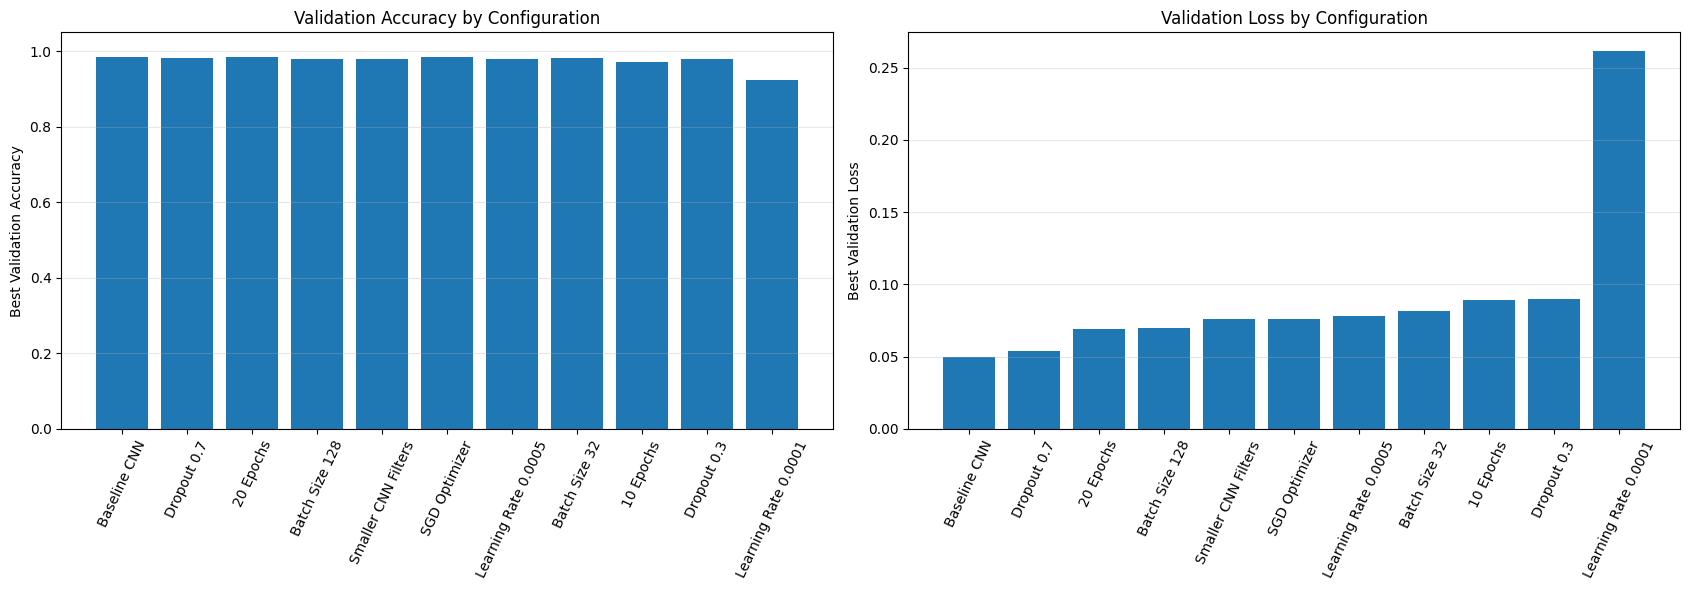

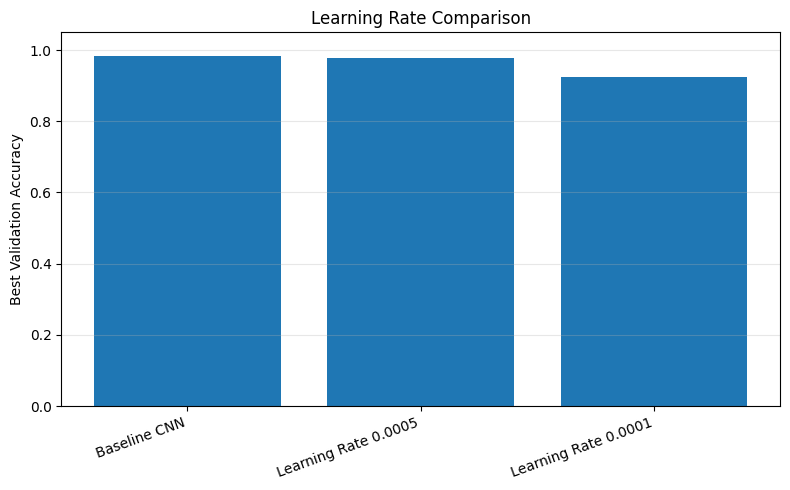

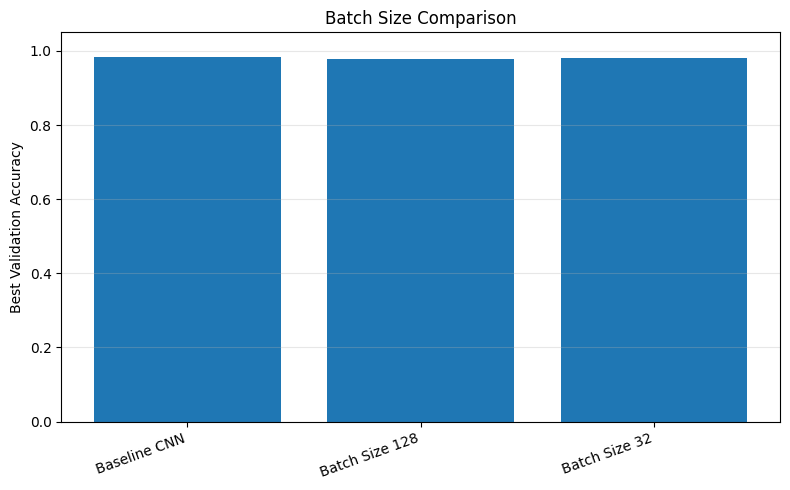

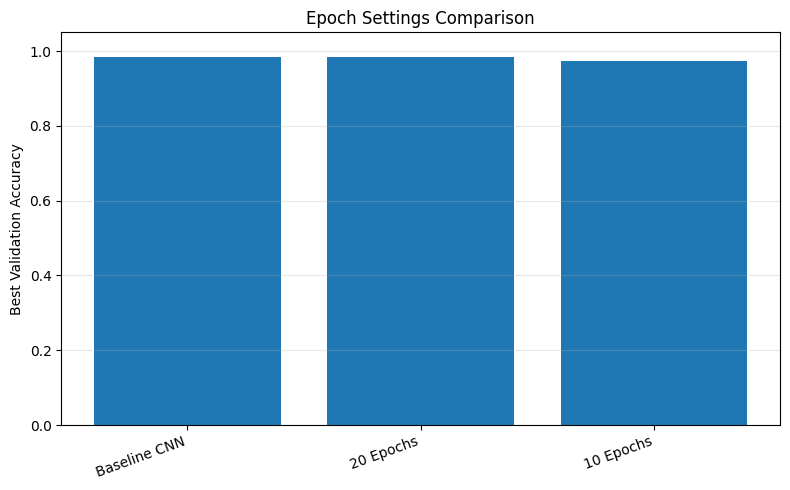

Comparison tables and plots saved to: /content/drive/MyDrive/Traffic_Sign_Project_Optimization_v2


In [5]:
# ==========================================
# 5.4 Compare experimental configurations
# ==========================================

results_df = pd.read_csv(RESULTS_CSV)
results_df = results_df.sort_values(
    ["Best Validation Loss", "Best Validation Accuracy"],
    ascending=[True, False]
).reset_index(drop=True)

display(
    results_df.style.format({
        "Learning Rate": "{:.5f}",
        "Best Validation Accuracy": "{:.4f}",
        "Best Validation Loss": "{:.4f}",
        "Training Time (seconds)": "{:.1f}"
    })
)

# Overall configuration comparison.
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

axes[0].bar(
    results_df["Experiment"],
    results_df["Best Validation Accuracy"]
)
axes[0].set_title("Validation Accuracy by Configuration")
axes[0].set_ylabel("Best Validation Accuracy")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=65)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    results_df["Experiment"],
    results_df["Best Validation Loss"]
)
axes[1].set_title("Validation Loss by Configuration")
axes[1].set_ylabel("Best Validation Loss")
axes[1].tick_params(axis="x", rotation=65)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    OPTIMIZATION_DIR / "all_configurations_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Learning-rate comparison.
lr_names = [
    "Baseline CNN",
    "Learning Rate 0.0005",
    "Learning Rate 0.0001"
]
lr_df = results_df[results_df["Experiment"].isin(lr_names)].copy()

plt.figure(figsize=(8, 5))
plt.bar(
    lr_df["Experiment"],
    lr_df["Best Validation Accuracy"]
)
plt.title("Learning Rate Comparison")
plt.ylabel("Best Validation Accuracy")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    OPTIMIZATION_DIR / "learning_rate_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Batch-size comparison.
batch_names = [
    "Baseline CNN",
    "Batch Size 32",
    "Batch Size 128"
]
batch_df = results_df[results_df["Experiment"].isin(batch_names)].copy()

plt.figure(figsize=(8, 5))
plt.bar(
    batch_df["Experiment"],
    batch_df["Best Validation Accuracy"]
)
plt.title("Batch Size Comparison")
plt.ylabel("Best Validation Accuracy")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    OPTIMIZATION_DIR / "batch_size_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Epoch-setting comparison.
epoch_names = [
    "Baseline CNN",
    "10 Epochs",
    "20 Epochs"
]
epoch_df = results_df[results_df["Experiment"].isin(epoch_names)].copy()

plt.figure(figsize=(8, 5))
plt.bar(
    epoch_df["Experiment"],
    epoch_df["Best Validation Accuracy"]
)
plt.title("Epoch Settings Comparison")
plt.ylabel("Best Validation Accuracy")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    OPTIMIZATION_DIR / "epoch_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Comparison tables and plots saved to:", OPTIMIZATION_DIR)

## 5.5 Select the Best Hyperparameter Configuration

The best configuration is selected using the lowest validation loss. If two configurations have the same loss, the higher validation accuracy is preferred. The test set is not involved in this decision.

In [6]:

# 5.5 Select the Best Hyperparameter Configuration

results_df = pd.read_csv(RESULTS_CSV)

# Exclude the baseline: select the best tuning experiment only.
tuning_results = results_df[
    results_df["Experiment"] != "Baseline CNN"
].copy()

# Select the lowest validation loss.
best_config = tuning_results.sort_values(
    by=["Best Validation Loss", "Best Validation Accuracy"],
    ascending=[True, False]
).iloc[0]

print("Selected Best Hyperparameter Configuration:")
display(best_config.to_frame("Value"))

# Save the selected configuration.
best_config.to_frame("Value").to_csv(
    OPTIMIZATION_DIR / "best_hyperparameter_configuration.csv"
)

print("\nBest configuration saved successfully.")


Selected Best Hyperparameter Configuration:


,Value
Experiment,Dropout 0.7
Learning Rate,0.001
Batch Size,64
Optimizer,Adam
Dropout,0.7
Filters,"[32, 64, 128]"
Max Epochs,20
Epochs Completed,20
Best Loss Epoch,18
Best Accuracy Epoch,16



Best configuration saved successfully.


## 5.6 Retrain and Save the Optimized CNN

After selecting the best configuration, a final CNN is trained using the selected hyperparameters. Training and validation data are used here; the official test set remains untouched until the next section.

In [8]:
# ==========================================
# 5.6 Retrain and Save the Optimized CNN
# ==========================================

# Recover the selected configuration as a proper dictionary.
selected_experiment = str(best_config["Experiment"])

if selected_experiment == "Baseline CNN":
    best_config = BASELINE_CONFIG.copy()
else:
    matching_configs = [
        config for config in TUNING_CONFIGS
        if config["Experiment"] == selected_experiment
    ]

    if not matching_configs:
        raise ValueError(
            f"Configuration not found: {selected_experiment}"
        )

    best_config = matching_configs[0].copy()

# Validate the configuration before training.
assert isinstance(best_config["Filters"], list)
assert len(best_config["Filters"]) == 3

print("Final selected configuration:")
print(best_config)

# Clear previous model state to reduce memory usage.
keras.backend.clear_session()
gc.collect()

# Create training and validation datasets.
final_train_ds = make_path_dataset(
    train_paths,
    train_labels,
    batch_size=int(best_config["Batch Size"]),
    training=True
)

final_val_ds = make_path_dataset(
    val_paths,
    val_labels,
    batch_size=int(best_config["Batch Size"]),
    training=False
)

# Build and compile the optimized CNN.
optimized_cnn_model = build_tuned_cnn(best_config)

optimized_cnn_model.compile(
    optimizer=create_optimizer(best_config),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Training callbacks.
final_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# Train using training and validation sets only.
start_time = time.time()

optimized_history = optimized_cnn_model.fit(
    final_train_ds,
    validation_data=final_val_ds,
    epochs=int(best_config["Max Epochs"]),
    callbacks=final_callbacks,
    verbose=1
)

final_training_time = time.time() - start_time

# Save the optimized model and its training history.
OPTIMIZED_MODEL_PATH = (
    OPTIMIZATION_DIR / "optimized_cnn_gtsrb.keras"
)

optimized_cnn_model.save(OPTIMIZED_MODEL_PATH)

pd.DataFrame(
    optimized_history.history
).to_csv(
    OPTIMIZATION_DIR / "optimized_cnn_training_history.csv",
    index=False
)

# Save the exact selected configuration.
with open(
    OPTIMIZATION_DIR / "final_selected_configuration.json",
    "w"
) as file:
    json.dump(best_config, file, indent=4)

print("\nOptimized CNN training completed!")
print("Selected experiment:", selected_experiment)
print("Model saved:", OPTIMIZED_MODEL_PATH)
print("Epochs completed:", len(optimized_history.history["loss"]))
print(
    "Best validation accuracy:",
    round(max(optimized_history.history["val_accuracy"]), 5)
)
print(
    "Best validation loss:",
    round(min(optimized_history.history["val_loss"]), 5)
)
print("Training time (seconds):", round(final_training_time, 1))


Final selected configuration:
{'Experiment': 'Dropout 0.7', 'Learning Rate': 0.001, 'Batch Size': 64, 'Optimizer': 'Adam', 'Dropout': 0.7, 'Filters': [32, 64, 128], 'Max Epochs': 20}
Epoch 1/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 67s 116ms/step - accuracy: 0.2090 - loss: 2.8867 - val_accuracy: 0.4549 - val_loss: 1.7858 - learning_rate: 0.0010
Epoch 2/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 58s 110ms/step - accuracy: 0.3882 - loss: 1.9446 - val_accuracy: 0.5740 - val_loss: 1.2234 - learning_rate: 0.0010
Epoch 3/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 82s 110ms/step - accuracy: 0.4789 - loss: 1.5718 - val_accuracy: 0.7316 - val_loss: 0.8211 - learning_rate: 0.0010
Epoch 4/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 62s 117ms/step - accuracy: 0.5614 - loss: 1.3090 - val_accuracy: 0.8200 - val_loss: 0.5620 - learning_rate: 0.0010
Epoch 5/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 76s 107ms/step - accuracy: 0.6127 - loss: 1.1422 - val_accuracy: 0.8672 - val_loss: 0.4191 - learning_rate: 0.0010
Epoch 6/20
525/525 ━━━━━━━━━━━━━━━━━━━━ 57

### 5.7 Final Test Evaluation: Baseline CNN vs Optimized CNN

The official test set is used only after hyperparameter selection and final training. Both the saved baseline model and the optimized model are evaluated on the same test images for a fair comparison.

In [9]:
# ==========================================
# 5.7 Final Evaluation on the Official Test Set
# ==========================================

TEST_BATCH_SIZE = 64

# Prepare the official test dataset
test_ds = make_path_dataset(
    test_paths,
    test_labels,
    batch_size=TEST_BATCH_SIZE,
    training=False
)

# Compile the restored baseline model for evaluation
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Evaluate both models
baseline_test_metrics = baseline_model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

optimized_test_metrics = optimized_cnn_model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

# Predict labels for both models
y_true = np.asarray(test_labels, dtype=np.int32)

baseline_probabilities = baseline_model.predict(
    test_ds,
    verbose=1
)
baseline_predictions = np.argmax(baseline_probabilities, axis=1)

optimized_probabilities = optimized_cnn_model.predict(
    test_ds,
    verbose=1
)
optimized_predictions = np.argmax(optimized_probabilities, axis=1)

# Verify prediction counts
assert len(y_true) == len(baseline_predictions) == len(optimized_predictions), \
    "Mismatch between test labels and predictions."

# Calculate weighted Precision, Recall, and F1-score
def calculate_weighted_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1-Score": f1
    }

baseline_final_scores = calculate_weighted_metrics(
    y_true,
    baseline_predictions
)

optimized_final_scores = calculate_weighted_metrics(
    y_true,
    optimized_predictions
)

# Create final comparison table
final_comparison_df = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score"
    ],
    "Baseline CNN": [
        baseline_test_metrics["loss"],
        baseline_final_scores["Accuracy"],
        baseline_final_scores["Weighted Precision"],
        baseline_final_scores["Weighted Recall"],
        baseline_final_scores["Weighted F1-Score"]
    ],
    "Optimized CNN": [
        optimized_test_metrics["loss"],
        optimized_final_scores["Accuracy"],
        optimized_final_scores["Weighted Precision"],
        optimized_final_scores["Weighted Recall"],
        optimized_final_scores["Weighted F1-Score"]
    ]
})

final_comparison_df["Difference"] = (
    final_comparison_df["Optimized CNN"]
    - final_comparison_df["Baseline CNN"]
)

display(
    final_comparison_df.style.format({
        "Baseline CNN": "{:.4f}",
        "Optimized CNN": "{:.4f}",
        "Difference": "{:+.4f}"
    })
)

# Save comparison results
final_comparison_df.to_csv(
    OPTIMIZATION_DIR / "baseline_vs_optimized_test_results.csv",
    index=False
)

# Display classification report
print("\nOptimized CNN Classification Report:")
print(
    classification_report(
        y_true,
        optimized_predictions,
        zero_division=0
    )
)

print("\nFinal test comparison saved successfully.")

198/198 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - accuracy: 0.9827 - loss: 0.0672
198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.9710 - loss: 0.1412
198/198 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step
198/198 ━━━━━━━━━━━━━━━━━━━━ 11s 52ms/step


,Metric,Baseline CNN,Optimized CNN,Difference
0,Test Loss,0.0672,0.1412,+0.0740
1,Accuracy,0.9827,0.9710,-0.0117
2,Weighted Precision,0.9835,0.9723,-0.0112
3,Weighted Recall,0.9827,0.9710,-0.0117
4,Weighted F1-Score,0.9824,0.9705,-0.0119



Optimized CNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.88      0.94        60
           1       0.98      1.00      0.99       720
           2       0.98      1.00      0.99       750
           3       0.99      0.94      0.96       450
           4       0.99      0.99      0.99       660
           5       0.90      0.99      0.94       630
           6       0.98      0.98      0.98       150
           7       1.00      0.98      0.99       450
           8       0.97      0.94      0.96       450
           9       1.00      0.96      0.98       480
          10       0.98      1.00      0.99       660
          11       0.93      0.97      0.95       420
          12       1.00      1.00      1.00       690
          13       1.00      1.00      1.00       720
          14       1.00      1.00      1.00       270
          15       0.99      1.00      0.99       210
          16       0.99      1.00      0.99

### 5.8 Final Performance Visualization

The final plot compares the baseline CNN and optimized CNN on the official test set. These are the final values to use when discussing whether optimization improved the model.

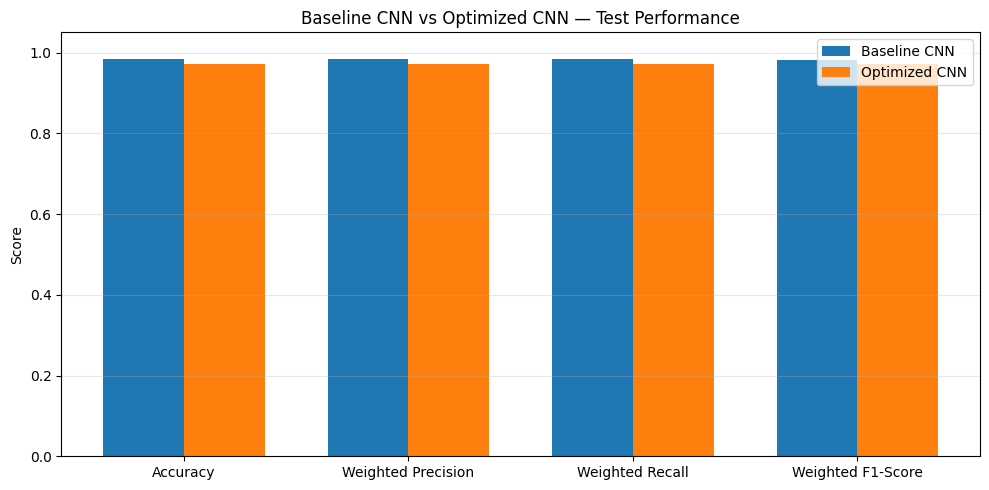

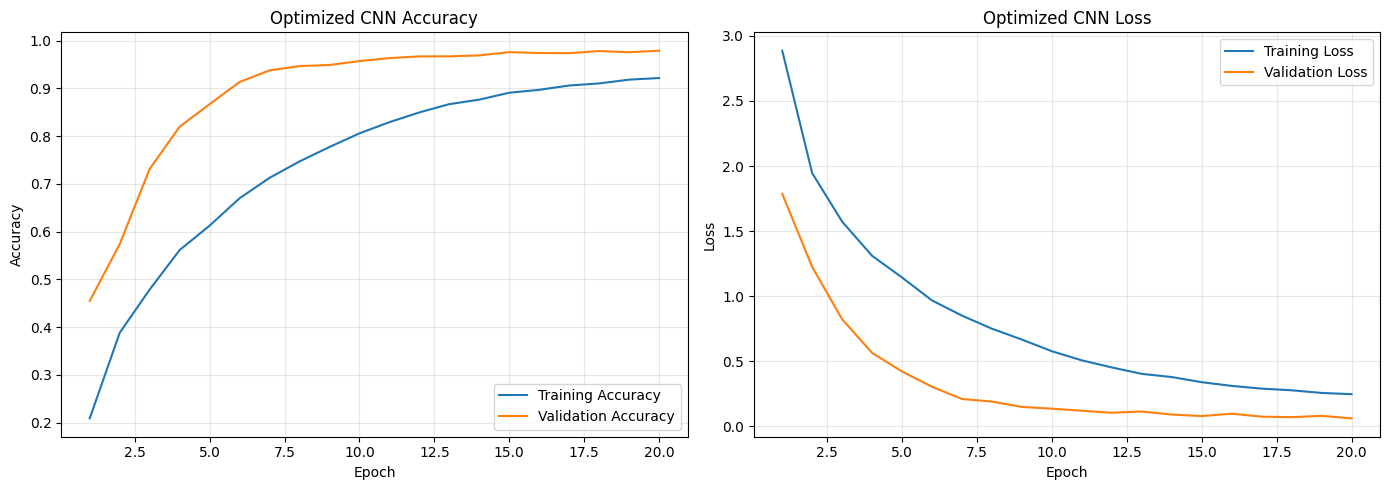

All Part 5 outputs are saved in:
/content/drive/MyDrive/Traffic_Sign_Project_Optimization_v2


In [15]:
# ==========================================
# 5.8 Final Performance Plots
# ==========================================

metrics = [
    "Accuracy",
    "Weighted Precision",
    "Weighted Recall",
    "Weighted F1-Score"
]

# Extract metrics using the Metric column
plot_df = final_comparison_df.set_index("Metric")

baseline_values = plot_df.loc[metrics, "Baseline CNN"].to_numpy()
optimized_values = plot_df.loc[metrics, "Optimized CNN"].to_numpy()

x = np.arange(len(metrics))
width = 0.36


# ------------------------------------------
# Plot 1: Baseline vs Optimized CNN
# ------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Baseline CNN"
)

plt.bar(
    x + width / 2,
    optimized_values,
    width,
    label="Optimized CNN"
)

plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Baseline CNN vs Optimized CNN — Test Performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OPTIMIZATION_DIR / "baseline_vs_optimized_test_plot.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------
# Plot 2: Optimized CNN Learning Curves
# ------------------------------------------

final_history_df = pd.DataFrame(optimized_history.history)

epochs_range = range(1, len(final_history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    epochs_range,
    final_history_df["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs_range,
    final_history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Optimized CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)


# Loss
axes[1].plot(
    epochs_range,
    final_history_df["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs_range,
    final_history_df["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Optimized CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OPTIMIZATION_DIR / "optimized_cnn_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------
# Save Confirmation
# ------------------------------------------

print("All Part 5 outputs are saved in:")
print(OPTIMIZATION_DIR)